<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QVC_RadioSignalAdversarial_Wu2023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QVC for radio-signal classification under adversarial attack: Wu et al. (2023) step by step

This notebook re-implements, runs and checks the method of

> Yanqiu Wu, Eromanga Adermann, Chandra Thapa, Seyit Camtepe, Hajime Suzuki and Muhammad Usman,
> "Radio Signal Classification by Adversarially Robust Quantum Machine Learning",
> CSIRO Data61, Research Square preprint rs-3842432/v1, 9 January 2024. https://doi.org/10.21203/rs.3.rs-3842432/v1

The paper publishes no code ("data available on reasonable request"), so everything below is written from the method as the
38-page preprint describes it: a quantum variational classifier (QVC) on 8 qubits that reads a radio signal through
amplitude encoding, a classical CNN, three adversarial attacks (FGSM, PGD, universal perturbation) in the white-box and the
black-box (transfer) setting, an approximate amplitude encoding (AAE) that replaces the deep exact state-preparation circuit by a
5-layer trained one, a Kolmogorov-Smirnov test of how detectable the attacks are, and a depolarising-noise study.

**What the notebook does.** It downloads real RML2016.10a signals (8PSK, GFSK and CPFSK at 16 dB SNR), generates the paper's
synthetic Fourier-series waveforms (square, sawtooth, triangle), trains a CNN and a 30-layer QVC on three tasks (binary RML,
3-class RML, 3-class synthetic), attacks both with FGSM, PGD and UAP at a grid of perturbation-to-signal ratios (PSR), transfers
the attacks from one model to the other, builds the AAE-QVC, repeats the key experiments of the paper (Tables 1, 2, 3, A3 and
Figs. 3, 4, 6) and ends with a verdict per claim. Because a robust-looking curve can come from *gradient masking* or from plain
insensitivity, it also runs stronger and different attacks (a margin-loss PGD, random restarts, a random-noise control,
transfer to a random forest and an SVM) and says whether the paper's conclusion survives them.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs
PennyLane (Colab already has PyTorch, NumPy, scikit-learn and Matplotlib). No GPU, no IBM account and no token are needed: the
data come from a public GitHub backup of RML2016.10a. All quantum circuits are simulated *exactly* (no shot noise) by a small
vectorised PyTorch simulator that the notebook asserts equal to the PennyLane circuit it implements.

**Runtime and what was executed.** The committed outputs are from `FAST_MODE = True` (150 test and 300 training+validation signals per class, 40 QVC epochs, 60 Adam iterations per AAE signal, subsets for the AAE experiments). It ran top to bottom without error in 32 minutes on one CPU thread of a heavily shared laptop (several other jobs were using all cores; the same path took about 10 minutes in an earlier, less loaded trial). `FAST_MODE = False` is the paper-sized budget (200 test and 800 training+validation signals per class, 80 QVC epochs, 300 AAE iterations, all five encoder depths, ten fidelity repetitions, three split seeds for the classical models); it is coded and its budgets are listed in the configuration cell, but it was **not executed** because on this machine it would take several hours (the training cell alone had not finished after 32 minutes under the same load), so every number below comes from the FAST run and has the small-sample uncertainty of a few dozen to a few hundred test signals.

**What you get at the end.** The paper's Table 1 (accuracy of CNN, QVC-30 and 5AAE-QVC-30), Table 2 (fidelity and accuracy
against the number of encoding layers), Table 3 (share of detectable adversarial examples) and Table A3 (parameter counts)
re-computed; the white-box and black-box accuracy-versus-PSR figures re-drawn; the noise study; gradient-masking diagnostics; a
side-by-side comparison with a verdict per claim; a critical reading; and five exercises.

## The paper in one page

**Problem.** Automatic modulation classification (AMC) decides from the I/Q samples of a received packet which modulation scheme
the transmitter used. Deep-learning AMC is known to be fragile: a small, deliberately crafted perturbation
(Sadeghi and Larsson 2018) makes it mislabel the signal. Earlier quantum-adversarial work (West et al. 2023) found that quantum
variational classifiers resist attacks crafted on classical networks for *images*; nobody had tested radio signals.

**Decision.** Given a signal x (256 numbers), output one of C modulation classes. The attacker adds a perturbation r of power
P_r; the attack strength is the perturbation-to-signal ratio PSR = 10 log10(P_r / P_signal) in dB.

**Method.**
- *QVC.* 256 amplitudes -> 8 qubits by amplitude encoding (exact, or approximate = AAE). Then 30 layers; each layer has RX, RZ, RY on
  every wire followed by CNOTs between neighbouring wires. Adam, learning rate 5e-3, batch 256 (Table A1).
- *AAE.* A 5-layer circuit (24 angles per layer, RX-RZ-RY plus CNOTs) is trained *per signal* with Adam (step 0.1, 300 iterations,
  betas 0.9/0.99) so that its output state approximates the exact amplitude-encoded state (fidelity about 0.89-0.90); 155 gates
  instead of about 973.
- *CNN.* Pad (0,2), Conv(1->32, 1x3), ReLU, dropout 0.2, FC(16), FC(C); Adam 1e-3, batch 256 (Table A2); 133,298 / 133,315 parameters.
- *Attacks.* FGSM, PGD (random start + signed-gradient steps) and the PCA-based universal perturbation (UAP); white-box (gradient
  of the attacked model) and black-box (craft on the other model, apply to the victim).
- *Detectability.* A two-sample Kolmogorov-Smirnov test (alpha = 0.05) between an adversarial signal and the original signals; an
  attack is "imperceptible" if at least one original signal is statistically indistinguishable (Algorithm 2).
- *Noise.* A depolarising channel (p = 0.02) on every qubit after every layer of the AAE-QVC.

**Data.** RML2016.10a (O'Shea and West 2016): 8PSK vs GFSK (binary) and 8PSK vs GFSK vs CPFSK (3-class) at SNR = 16 dB, 5000
training and 500 test signals per class; plus a synthetic Fourier-series dataset (square, sawtooth, triangle waves; 5000 + 500 per
class).
**Claims (what is checked at the end).**
1. Table 1: accuracy CNN / QVC-30 / 5AAE-QVC-30 = 0.995 / 0.993 / 0.992 (binary RML), 0.967 / 0.812 / 0.775 (3-class RML), 0.998 / 0.902 / 0.881 (synthetic).
2. Table 2: fidelity 0.731, 0.895, 0.944, 0.951, 0.988 and accuracy 0.746, 0.775, 0.779, 0.785, 0.803 for 3, 5, 10, 15, 20 AAE layers (exact 0.812); 31 gates per layer, 973 gates for exact encoding.
3. Mean fidelity 0.8957 +- 0.0003 for 5 layers over 10 repetitions.
4. Table A3: 133,298 / 133,315 CNN parameters, 1,933 QVC-30 and 1,115 5AAE-QVC-30 gates.
5. White-box (Fig. 3): QVC is generally slightly more robust than the CNN but still collapses at high PSR.
6. Black-box (Fig. 4): attacks crafted on the QVC transfer to the CNN (3-class PGD: CNN 96.7 % -> 43.4 %); attacks crafted on the CNN do not fool the QVC / AAE-QVC.
7. Table 3: share of detectable adversarial examples (QVC-crafted lower than CNN-crafted for FGSM and PGD, the reverse for UAP).
8. Fig. 6: 2 % depolarising noise lowers the AAE-QVC accuracy a lot but leaves its resistance to CNN-crafted attacks intact.

## What follows the paper and what had to be chosen

The preprint leaves many details open. Every choice below is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Source of RML2016.10a | deepsig.ai (registration) | Public GitHub backup `dannis999/RML2016.10a` (one text file per modulation and SNR, 1000 x 128 I/Q); the official pickle is used instead if `RML2016.10a_dict.pkl` is placed in `DATA_DIR` |
| Samples per class | 5000 train + 500 test at 16 dB | RML2016.10a has only **1000 signals per modulation and SNR**, so 800 are used for training and validation and 200 for testing per class (FAST mode: fewer) |
| Synthetic dataset | square / sawtooth / triangle, random frequency, Gaussian noise | same three classes; 10 Fourier terms, 2-6 cycles per 256 samples, random phase, amplitude 0.05-0.10, noise sigma 0.01 (the ranges are not given) |
| Input vector | 128 I + 128 Q = 256 numbers | same, I followed by Q; the synthetic 256 samples are used as they are |
| Entangling pattern | "a CNOT connecting two adjacent wires" | ring of 8 CNOTs per QVC layer and open chain of 7 CNOTs per AAE layer: the only reading consistent with Table A3 (1,933 = 973 + 30 x 32; 1,115 = 155 + 30 x 32) |
| Read-out | not stated | expectation value of Pauli-Z on the first C wires = the C logits, softmax cross-entropy |
| QVC starting angles | not stated | N(0, 0.1^2), chosen on the validation loss in a pilot |
| Epochs | not stated | 80 (QVC), 50 (CNN) in the full run, keeping the epoch with the best validation loss |
| CNN input scaling | not stated | one global constant (training-set standard deviation) |
| AAE starting angles | not stated | uniform in [0, 2 pi) (lands at the paper's fidelity; small angles give about 0.93) |
| AAE parameters | "5 layers, 360 trainable parameters" | 5 layers x 8 wires x 3 angles = 120 (the 360 in the text does not follow from 24 per layer) |
| AAE-QVC training | on all AAE-encoded training signals | fine-tuned from the trained QVC on a subset (compute); adversarial signals are re-encoded with warm-started angles |
| PSR definition | 10 log10(P/S) | per-signal power for FGSM/PGD (L-infinity budget eps = rms(x) x 10^(PSR/20)); dataset power for UAP |
| PGD | iterations and step size not stated | 10 steps of 2.5 eps / 10 with random start (Madry et al.) |
| Noise model | p = 0.02 depolarising on "every qubit and AAE and QVC layer" | after every layer of the encoder and of the classifier, density-matrix simulation, noise included in training |
| Statistics | one run | one seed (42) for the attacks; spread over seeds only for the cheap classical models |

## 0. Setup

The first cell installs PennyLane (the paper's library) when it is missing; the second cell holds every tunable constant. The
simulator, the attacks and the AAE are plain PyTorch.

In [1]:
import sys, subprocess, importlib.util
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1"], check=False)
    # Colab may ask to restart the session after this line; if so, restart and run all again.
else:
    print("PennyLane already installed - skipping the install.")

PennyLane already installed - skipping the install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = True           # True: class demo (a few minutes). False: the full budget of the table in Section 0.
SEED      = 42
DATA_DIR  = "rml_data"     # downloaded signals are cached here
RML_SNR_DB = 16            # the paper's SNR
HF_NOTE   = "No Hugging Face token is needed: the data come from a public GitHub backup of RML2016.10a."

# ---- fixed by the paper (Tables A1, A2, Section 4, 5.4) ----
N_QUBITS_NOTE = "8 qubits = 256 amplitudes = 128 I + 128 Q samples"
QVC_LAYERS, QVC_LR, QVC_BATCH = 30, 5e-3, 256
CNN_LR = 1e-3
AAE_LAYERS, AAE_LR = 5, 0.1
NOISE_P = 0.02
KS_ALPHA = 0.05
PAPER_PSR_GRID = [-60, -48, -36, -24, -12, 0]     # the x axis of Figs. 3, 4 and 6
TOL = 0.02                                         # a claim is "reproduced" within 2 accuracy points

# ---- budgets: (FAST, FULL) ----
def pick(fast, full):
    return fast if FAST_MODE else full

TEST_PER_CLASS   = pick(150, 200)           # test signals per class (RML2016.10a has 1000 per class and SNR)
POOL_CAP         = pick(300, 800)           # train+validation signals per class (10 % validation)
SYN_PER_CLASS    = pick(500, 1000)          # synthetic signals per class (test + train + validation)
QVC_EPOCHS       = pick(40, 80)
CNN_EPOCHS       = pick(40, 50)
PSR_GRID         = pick([-48, -36, -24, -12, 0], PAPER_PSR_GRID)
PGD_STEPS        = pick(5, 10)
N_ATTACK         = pick(150, 400)           # test signals attacked per task (cap)
ADAPT_LEVELS     = pick([-24, -12], [-36, -24, -12])   # levels for the margin-loss and random-restart attacks
PGD_RESTARTS     = pick(2, 3)
UAP_SUBSET       = pick(150, 300)           # training signals the UAP adversary collects
AAE_ITERS        = pick(60, 300)            # Adam iterations per signal (paper: 300)
AAE_TRAIN_PER_CLASS = pick(24, 120)         # training signals encoded for the AAE-QVC
AAE_TEST_PER_CLASS  = pick(24, 100)         # test signals encoded for the AAE-QVC
AAE_FT_EPOCHS    = pick(6, 30)              # fine-tuning epochs of the AAE-QVC
AAE_ADV_N        = pick(30, 120)            # adversarial signals re-encoded per attack and PSR
AAE_ADV_ITERS    = pick(30, 100)            # warm-started iterations for adversarial signals
T2_DEPTHS        = pick([3, 5], [3, 5, 10, 15, 20])
T2_TRAIN_PER_CLASS, T2_TEST_PER_CLASS = pick((12, 20), (40, 50))
FID_N, FID_REPEATS = pick((12, 3), (60, 10))
NOISE_TRAIN_PER_CLASS = pick(10, 60)
NOISE_TEST_N     = pick(18, 60)
NOISE_STEPS      = pick(2, 25)
KS_N_ADV, KS_N_ORIG = pick((45, 90), (150, 300))
SEEDS_CLASSICAL  = pick([42], [42, 43, 44])
print("FAST_MODE =", FAST_MODE)

FAST_MODE = True


In [3]:
import os, time, warnings, urllib.parse
import numpy as np, pandas as pd, requests
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
import scipy, sklearn
import pennylane as qml
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

warnings.filterwarnings("ignore")
torch.set_num_threads(1)                      # one CPU thread: reproducible timings, polite on shared machines
np.random.seed(SEED); torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})
COL = {"QVC": "#6a3d9a", "CNN": "#1f78b4", "AAE-QVC": "#222222", "noisy": "#ff7f00", "RF": "#33a02c", "SVC": "#e31a1c"}
print("numpy", np.__version__, "| torch", torch.__version__, "| pennylane", qml.__version__, "| scipy", scipy.__version__,
      "| sklearn", sklearn.__version__)

numpy 2.5.4 | torch 2.14.1+cpu | pennylane 0.45.1 | scipy 1.18.1 | sklearn 1.9.1


## 1. The data: real RML2016.10a signals and the paper's synthetic waveforms

**RML2016.10a** (O'Shea and West 2016; licence CC BY-NC-SA 4.0, DeepSig) holds 1000 signals for each of 11 modulations at each of
20 SNRs (-20 ... 18 dB). Each signal is 128 complex samples (I and Q). The paper takes **8PSK, GFSK and CPFSK at SNR = 16 dB**. The
three text files used here (about 4.4 MB each) come from an unofficial GitHub backup of the dataset; the loader checks the shape
(1000 x 128 complex) and caches the arrays as `.npy`. If you have the official `RML2016.10a_dict.pkl`, put it in `DATA_DIR` and
it is used instead.

The paper says it sampled 5000 training and 500 test signals per class, which is impossible at one SNR in RML2016.10a (1000
per class); the notebook uses 200 test signals per class and the remaining 800 for training (90 %) and validation (10 %).

**The synthetic Fourier-series dataset** is generated, as in the paper, from square, sawtooth and triangle waves (partial Fourier
sums) with random frequency and phase plus Gaussian noise. It is a *generated* dataset by construction, its labels are the
wave shape that generated each signal.

In [4]:
RML_URLS = [  # CHOICE: an unofficial GitHub backup of RML2016.10a (one text file per modulation/SNR, 1000 x 128 complex I/Q)
    "https://raw.githubusercontent.com/dannis999/RML2016.10a/HEAD/2016.10a/{name}",
    "https://cdn.jsdelivr.net/gh/dannis999/RML2016.10a@main/2016.10a/{name}",
]

def _parse_rml_txt(text):
    rows = [[complex(t) for t in line.split()] for line in text.splitlines() if line.strip()]
    z = np.array(rows)                                          # (1000, 128) complex
    return np.concatenate([z.real, z.imag], axis=1).astype(np.float32)   # (1000, 256) = [I(128), Q(128)]

def load_rml_class(mod, snr, data_dir):
    """Return the 1000 real RML2016.10a signals of one modulation at one SNR as an array (1000, 256) = [I, Q]."""
    cache = os.path.join(data_dir, f"rml2016a_{mod}_{snr}dB.npy")
    if os.path.exists(cache):
        return np.load(cache)
    pk = os.path.join(data_dir, "RML2016.10a_dict.pkl")           # option: the official pickle placed in DATA_DIR
    if os.path.exists(pk):
        import pickle
        with open(pk, "rb") as fh:
            d = pickle.load(fh, encoding="latin1")
        x = d[(mod, snr)]                                         # (1000, 2, 128)
        arr = np.concatenate([x[:, 0], x[:, 1]], axis=1).astype(np.float32)
    else:
        name = urllib.parse.quote(f"{mod} {snr}.txt")
        arr, last = None, None
        for tmpl in RML_URLS:
            try:
                r = requests.get(tmpl.format(name=name), timeout=120)
                r.raise_for_status()
                arr = _parse_rml_txt(r.text)
                break
            except Exception as e:                                # try the next mirror
                last = e
        if arr is None:
            raise RuntimeError(f"could not download {mod} {snr} dB from any mirror: {last}")
    assert arr.shape == (1000, 256), arr.shape
    np.save(cache, arr)
    return arr

def make_synthetic(n_per_class, rng):
    """The paper's synthetic Fourier-series dataset: square, sawtooth and triangle waves, 256 samples each, with a random
    frequency, phase and amplitude and additive Gaussian noise. The paper does not give the ranges, so they are CHOICEs."""
    t = np.arange(256) / 256.0
    X, y = [], []
    for cls in range(3):
        for _ in range(n_per_class):
            f = rng.uniform(2.0, 6.0)                              # CHOICE: cycles per 256-sample window
            ph = rng.uniform(0, 2 * np.pi)
            amp = rng.uniform(0.05, 0.10)                          # CHOICE: Fig. C2 axis spans +-0.10
            w = 2 * np.pi * f * t + ph
            K = 10                                                 # CHOICE: number of Fourier terms
            if cls == 0:       # square wave
                s = (4 / np.pi) * sum(np.sin((2 * k - 1) * w) / (2 * k - 1) for k in range(1, K + 1))
            elif cls == 1:     # sawtooth wave
                s = (2 / np.pi) * sum(((-1) ** (k + 1)) * np.sin(k * w) / k for k in range(1, K + 1))
            else:              # triangle wave
                s = (8 / np.pi ** 2) * sum(((-1) ** k) * np.sin((2 * k + 1) * w) / (2 * k + 1) ** 2 for k in range(0, K))
            s = amp * s
            X.append(s + rng.normal(0, 0.01, 256))                 # CHOICE: noise sigma = 0.01
            y.append(cls)
    return np.array(X, dtype=np.float32), np.array(y)

In [5]:
RML_MODS = ["8PSK", "GFSK", "CPFSK"]
rml = {m: load_rml_class(m, RML_SNR_DB, DATA_DIR) for m in RML_MODS}
for m in RML_MODS:
    print(f"{m:6s} at {RML_SNR_DB} dB: array {rml[m].shape}, amplitude std {rml[m].std():.5f}, mean power per sample {np.mean(rml[m]**2):.2e}")
# sanity check that the text files really are RML2016.10a-like: the noise floor must grow as the SNR falls
lo = load_rml_class("8PSK", -20, DATA_DIR)
print(f"8PSK at -20 dB: amplitude std {lo.std():.5f} vs {rml['8PSK'].std():.5f} at 16 dB (a noisier signal has more power)")

def make_task(name, X, y, classes, seed):
    """Stratified split: n test signals per class, a capped pool of train+validation signals, 10 % of the pool for validation."""
    C = len(classes)
    Xp, Xte, yp, yte = train_test_split(X, y, test_size=TEST_PER_CLASS * C, stratify=y, random_state=seed)
    keep = np.concatenate([np.where(yp == c)[0][:POOL_CAP] for c in range(C)])
    Xp, yp = Xp[keep], yp[keep]
    Xtr, Xva, ytr, yva = train_test_split(Xp, yp, test_size=0.10, stratify=yp, random_state=seed)
    T = torch.tensor
    return dict(name=name, classes=classes, C=C, Xall=X, yall=y, Xtr=T(Xtr), ytr=T(ytr), Xva=T(Xva), yva=T(yva),
                Xte=T(Xte), yte=T(yte), scale=float(Xtr.std()))

TASKS = {}
X2 = np.concatenate([rml["8PSK"], rml["GFSK"]]); y2 = np.repeat([0, 1], 1000)
X3 = np.concatenate([rml[m] for m in RML_MODS]); y3 = np.repeat([0, 1, 2], 1000)
TASKS["Binary RML"] = make_task("Binary RML", X2, y2, ["8PSK", "GFSK"], SEED)
TASKS["3-class RML"] = make_task("3-class RML", X3, y3, RML_MODS, SEED)
Xs, ys = make_synthetic(SYN_PER_CLASS, np.random.default_rng(SEED))
TASKS["3-class synthetic"] = make_task("3-class synthetic", Xs, ys, ["square", "sawtooth", "triangle"], SEED)
for k, t in TASKS.items():
    print(f"{k:18s} train {len(t['Xtr']):5d}  val {len(t['Xva']):4d}  test {len(t['Xte']):4d}  classes {t['classes']}  input scale {t['scale']:.4f}")

8PSK   at 16 dB: array (1000, 256), amplitude std 0.00582, mean power per sample 3.38e-05
GFSK   at 16 dB: array (1000, 256), amplitude std 0.00553, mean power per sample 3.06e-05
CPFSK  at 16 dB: array (1000, 256), amplitude std 0.00555, mean power per sample 3.07e-05
8PSK at -20 dB: amplitude std 0.00625 vs 0.00582 at 16 dB (a noisier signal has more power)


Binary RML         train   540  val   60  test  300  classes ['8PSK', 'GFSK']  input scale 0.0057
3-class RML        train   810  val   90  test  450  classes ['8PSK', 'GFSK', 'CPFSK']  input scale 0.0057
3-class synthetic  train   810  val   90  test  450  classes ['square', 'sawtooth', 'triangle']  input scale 0.0569


## Dataset Exploration and Visualisation

Before any model is trained, the real data are looked at: shape, feature names, original labels and class counts, example
waveforms, and a 2-D projection of *real signals coloured by their ground-truth modulation*. The binary task is the 8PSK/GFSK
subset of the 3-class task, so its projection is the same picture with one colour fewer. The projection is fitted on the training
split only (PCA of the 256-dimensional vectors). The QVC does not use angle encoding (it uses amplitude encoding, so no [0, pi]
rescaling exists); the second panel therefore shows the same signals after the **L2 normalisation that amplitude encoding applies**,
which is what the quantum circuit actually receives.

feature vector (256) = 128 in-phase samples followed by 128 quadrature samples
feature names: ['I[0]', 'I[1]', 'I[2]'] ... ['I[126]', 'I[127]', 'Q[0]', 'Q[1]'] ... ['Q[126]', 'Q[127]']

Binary RML: array shape (2000, 256), label values [0, 1] = ['8PSK', 'GFSK'], counts {'8PSK': 1000, 'GFSK': 1000}
   split sizes: train 540, validation 60, test 300; min / max amplitude -0.1549 / 0.0726

3-class RML: array shape (3000, 256), label values [0, 1, 2] = ['8PSK', 'GFSK', 'CPFSK'], counts {'8PSK': 1000, 'GFSK': 1000, 'CPFSK': 1000}
   split sizes: train 810, validation 90, test 450; min / max amplitude -0.1549 / 0.0726

3-class synthetic: array shape (1500, 256), label values [0, 1, 2] = ['square', 'sawtooth', 'triangle'], counts {'square': 500, 'sawtooth': 500, 'triangle': 500}
   split sizes: train 810, validation 90, test 450; min / max amplitude -0.1400 / 0.1420


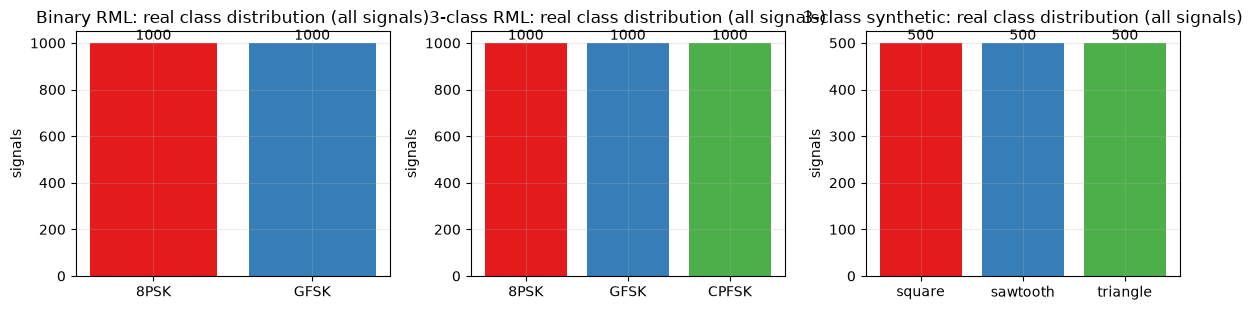

In [6]:
feat_names = [f"I[{t}]" for t in range(128)] + [f"Q[{t}]" for t in range(128)]
print("feature vector (256) = 128 in-phase samples followed by 128 quadrature samples")
print("feature names:", feat_names[:3], "...", feat_names[126:130], "...", feat_names[-2:])
rows = []
for k, t in TASKS.items():
    cnt = np.bincount(t["yall"], minlength=t["C"])
    print(f"\n{k}: array shape {t['Xall'].shape}, label values {sorted(set(t['yall'].tolist()))} = {t['classes']}, "
          f"counts {dict(zip(t['classes'], cnt.tolist()))}")
    print(f"   split sizes: train {len(t['Xtr'])}, validation {len(t['Xva'])}, test {len(t['Xte'])}; "
          f"min / max amplitude {t['Xall'].min():.4f} / {t['Xall'].max():.4f}")
fig, axs = plt.subplots(1, 3, figsize=(12, 3.2))
palette = ["#e41a1c", "#377eb8", "#4daf4a"]
for ax, (k, t) in zip(axs, TASKS.items()):
    cnt = np.bincount(t["yall"], minlength=t["C"])
    ax.bar(t["classes"], cnt, color=palette[:t["C"]])
    ax.set_title(f"{k}: real class distribution (all signals)"); ax.set_ylabel("signals")
    for i, c in enumerate(cnt): ax.text(i, c, str(c), ha="center", va="bottom")
plt.tight_layout(); plt.show()

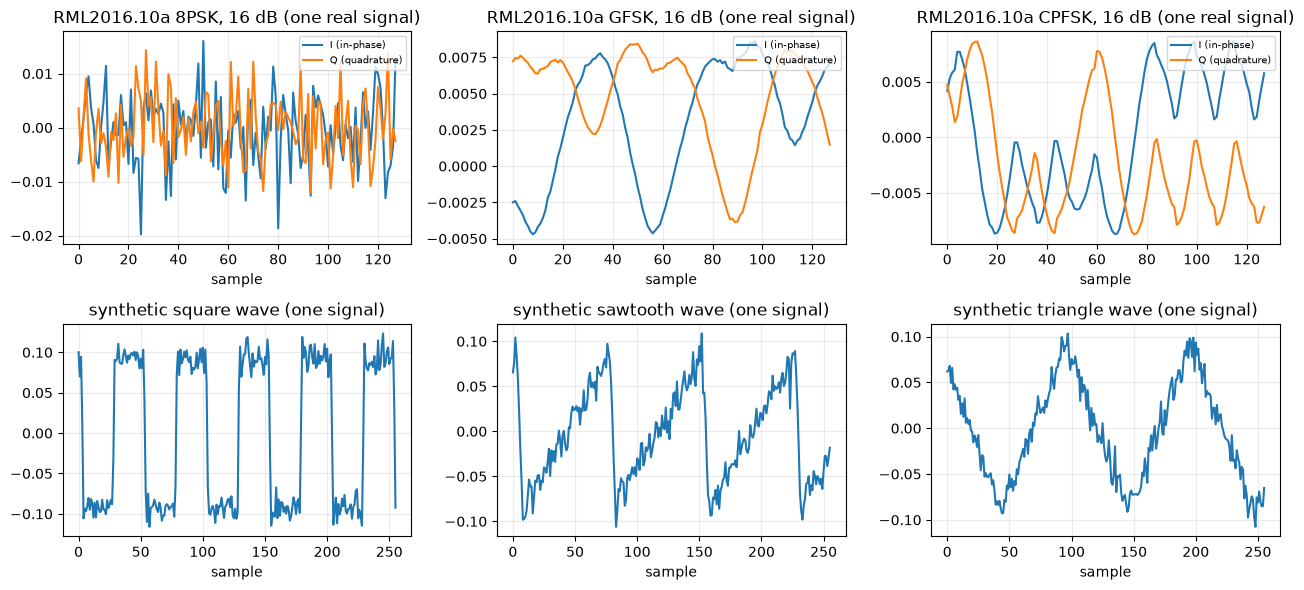

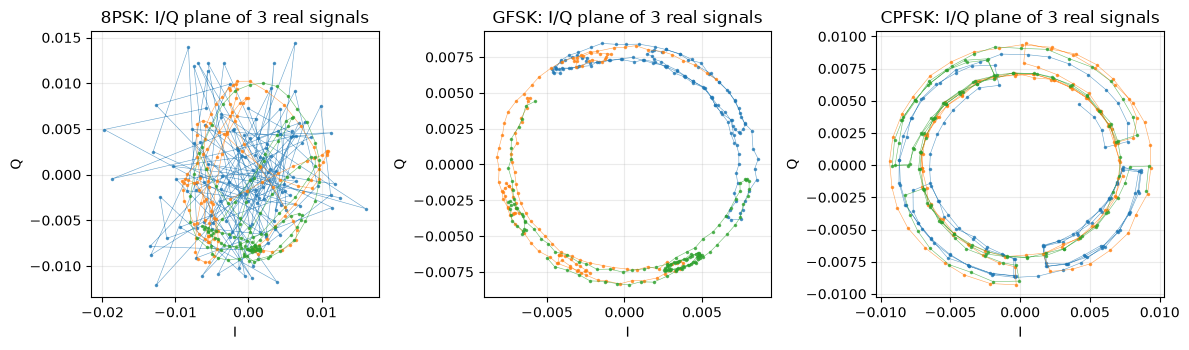

In [7]:
fig, axs = plt.subplots(2, 3, figsize=(13, 6))
t3 = TASKS["3-class RML"]
for c, m in enumerate(t3["classes"]):
    x = t3["Xall"][t3["yall"] == c][0]
    axs[0, c].plot(x[:128], label="I (in-phase)"); axs[0, c].plot(x[128:], label="Q (quadrature)")
    axs[0, c].set_title(f"RML2016.10a {m}, {RML_SNR_DB} dB (one real signal)"); axs[0, c].set_xlabel("sample"); axs[0, c].legend(loc="upper right", fontsize=7)
ts = TASKS["3-class synthetic"]
for c, m in enumerate(ts["classes"]):
    axs[1, c].plot(ts["Xall"][ts["yall"] == c][0]); axs[1, c].set_title(f"synthetic {m} wave (one signal)"); axs[1, c].set_xlabel("sample")
plt.tight_layout(); plt.show()
fig, axs = plt.subplots(1, 3, figsize=(12, 3.6))
for c, m in enumerate(t3["classes"]):
    for x in t3["Xall"][t3["yall"] == c][:3]:
        axs[c].plot(x[:128], x[128:], ".-", ms=3, lw=0.4, alpha=0.7)
    axs[c].set_title(f"{m}: I/Q plane of 3 real signals"); axs[c].set_xlabel("I"); axs[c].set_ylabel("Q")
plt.tight_layout(); plt.show()

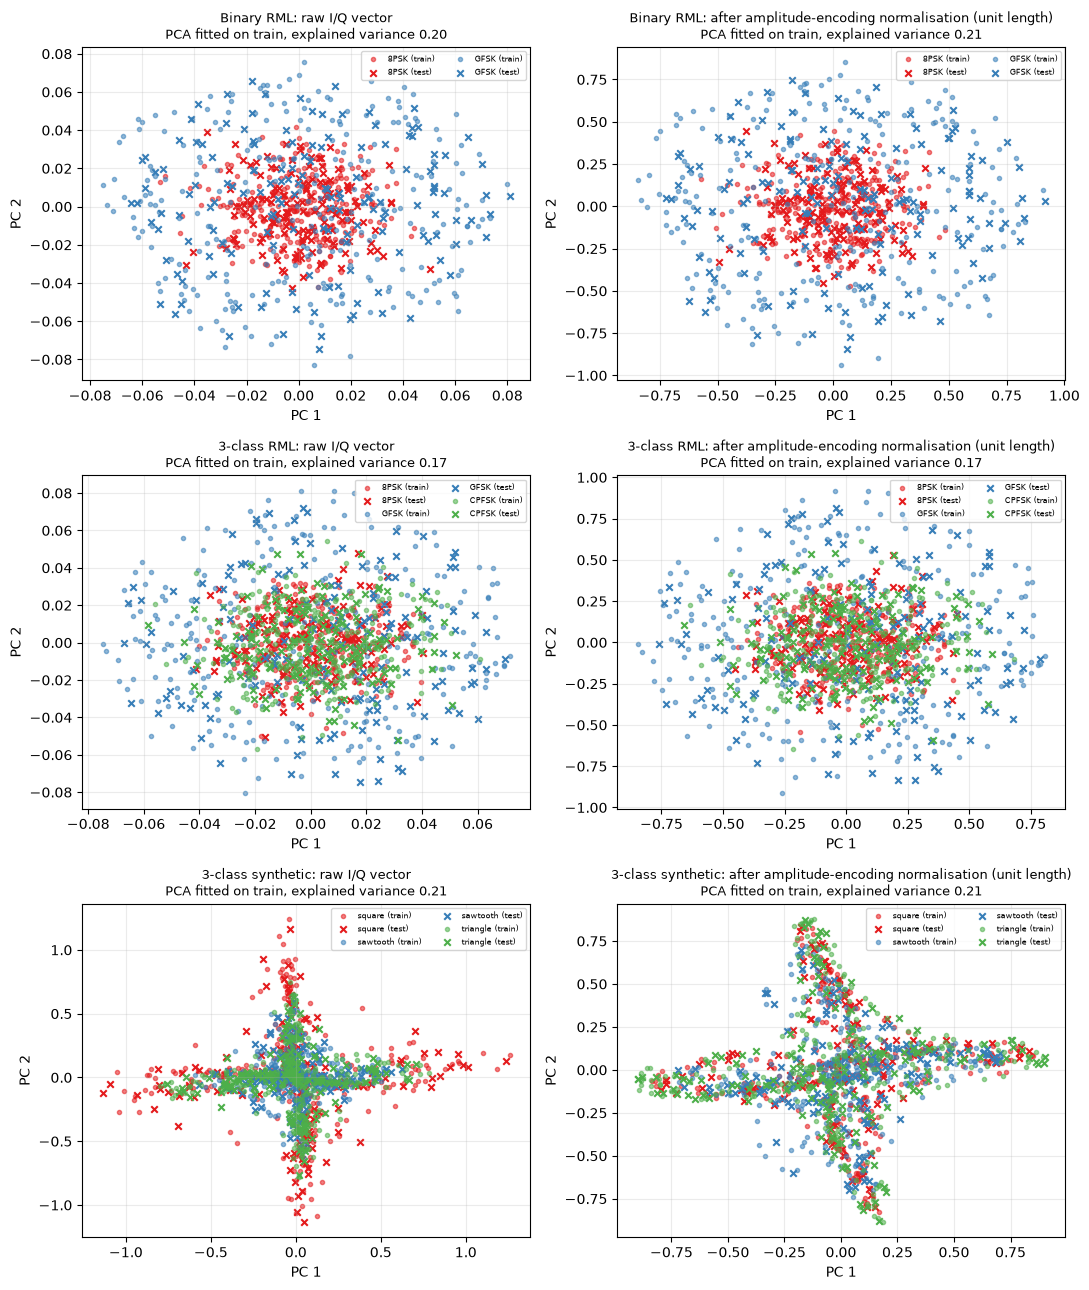

In [8]:
fig, axs = plt.subplots(3, 2, figsize=(11, 13))
for r, (k, t) in enumerate(TASKS.items()):
    Xtr_np, ytr_np = t["Xtr"].numpy(), t["ytr"].numpy()
    Xte_np, yte_np = t["Xte"].numpy(), t["yte"].numpy()
    for col, (title, f) in enumerate([("raw I/Q vector", lambda a: a),
                                      ("after amplitude-encoding normalisation (unit length)", lambda a: a / np.linalg.norm(a, axis=1, keepdims=True))]):
        pca = PCA(n_components=2, random_state=SEED).fit(f(Xtr_np))              # fitted on the training split only
        ztr, zte = pca.transform(f(Xtr_np)), pca.transform(f(Xte_np))
        ax = axs[r, col]
        for c, name in enumerate(t["classes"]):
            ax.scatter(*ztr[ytr_np == c].T, s=9, alpha=0.55, color=palette[c], label=f"{name} (train)")
            ax.scatter(*zte[yte_np == c].T, s=22, marker="x", color=palette[c], label=f"{name} (test)")
        ax.set_title(f"{k}: {title}\nPCA fitted on train, explained variance {pca.explained_variance_ratio_.sum():.2f}", fontsize=9)
        ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); ax.legend(fontsize=6, ncol=2)
plt.tight_layout(); plt.show()

## 2. An exact, fast simulator of the paper's circuits (checked against PennyLane)

Training a 30-layer circuit and attacking it thousands of times through PennyLane's general-purpose simulator would take days on one
CPU thread. Two facts make a much faster exact simulator possible:

1. With amplitude encoding the input state is simply the normalised signal, so a QVC is a fixed 256 x 256 unitary U(theta) applied to
   a state vector; the logits are <Z_c> = sum_k z_c[k] |(U x_hat)[k]|^2.
2. A layer is eight single-qubit rotations (one 2 x 2 matrix per wire, RX then RZ then RY) followed by a CNOT pattern, i.e. a
   tensor product of small matrices and a permutation of the basis states. The simulator applies them batched, in PyTorch (autograd
   gives exact input and parameter gradients).

The simulator is **exact** (no shot noise, no approximation). The next cell *asserts* that it equals the PennyLane circuits that
the paper describes, for random angles, on real signals. The same file also holds the density-matrix simulator used for the
noise study (Section 9), which is asserted against PennyLane's `default.mixed` device in the same way.

In [9]:
NQ, DIM = 8, 256                      # 8 qubits hold the 256 numbers (128 I + 128 Q) of one signal
CDT, RDT = torch.complex64, torch.float32   # CHOICE: single precision is enough and about 2x faster on one CPU thread

def _bits(k):                         # wire 0 is the most significant bit (PennyLane / Qiskit big-endian convention)
    return [(k >> (NQ - 1 - q)) & 1 for q in range(NQ)]

def cnot_gather_index(pairs):
    """Index vector g such that new_state = old_state[:, g] equals applying CNOT(c, t) for (c, t) in `pairs`, in order."""
    out = np.zeros(DIM, dtype=np.int64)               # old basis index k -> new basis index out[k]
    for k in range(DIM):
        b = _bits(k)
        for c, t in pairs:
            if b[c]:
                b[t] ^= 1
        out[k] = int("".join(map(str, b)), 2)
    g = np.zeros(DIM, dtype=np.int64)
    g[out] = np.arange(DIM)
    return torch.as_tensor(g)

# CHOICE: the paper says "a CNOT connecting two adjacent wires" per layer. Table A3 gate counts (1,933 = 973 + 30 x 32 and
# 1,115 = 155 + 30 x 32; encoding layer = 31 gates) are only consistent with 8 CNOTs (a ring) in a classifier layer and
# 7 CNOTs (an open chain) in an encoding layer, so that is what is built here.
RING = [(i, (i + 1) % NQ) for i in range(NQ)]
CHAIN = [(i, i + 1) for i in range(NQ - 1)]
G_RING, G_CHAIN = cnot_gather_index(RING), cnot_gather_index(CHAIN)

ZMAT = torch.tensor([[1.0 - 2.0 * _bits(k)[c] for c in range(NQ)] for k in range(DIM)], dtype=RDT)  # <Z_c> weights

def rot_mats(th):
    """th (..., 3) real angles -> (..., 2, 2) complex matrix of RX(th0) then RZ(th1) then RY(th2) (RX acts first)."""
    a, b, c = th[..., 0], th[..., 1], th[..., 2]
    ca, sa, cb, sb = torch.cos(a / 2), torch.sin(a / 2), torch.cos(b / 2), torch.sin(b / 2)
    cc, sc = torch.cos(c / 2), torch.sin(c / 2)
    r00, i00 = cc * ca * cb - sc * sa * sb, -cc * ca * sb + sc * sa * cb
    r01, i01 = -cc * sa * sb - sc * ca * cb, -cc * sa * cb - sc * ca * sb
    r10, i10 = sc * ca * cb + cc * sa * sb, -sc * ca * sb - cc * sa * cb
    r11, i11 = -sc * sa * sb + cc * ca * cb, -sc * sa * cb + cc * ca * sb
    re = torch.stack([torch.stack([r00, r01], -1), torch.stack([r10, r11], -1)], -2)
    im = torch.stack([torch.stack([i00, i01], -1), torch.stack([i10, i11], -1)], -2)
    return torch.complex(re, im).to(CDT)

def kron2(A, B):
    m, n = A.shape[-1], B.shape[-1]
    return (A[..., :, None, :, None] * B[..., None, :, None, :]).reshape(*A.shape[:-2], m * n, m * n)

def run_layers(state, theta, gather):
    """Apply L layers (RX, RZ, RY on every wire, then the CNOT pattern) to a batch of states (B, 256).
    theta (L, 8, 3): one circuit shared by the batch (the classifier). theta (B, L, 8, 3): one circuit per sample (AAE)."""
    U = rot_mats(theta)                                        # (..., L, 8, 2, 2)
    L, B = theta.shape[-3], state.shape[0]
    if theta.dim() == 3:                                       # two 4-qubit blocks (16 x 16) per layer
        Ka = kron2(kron2(U[..., 0, :, :], U[..., 1, :, :]), kron2(U[..., 2, :, :], U[..., 3, :, :]))
        Kb = kron2(kron2(U[..., 4, :, :], U[..., 5, :, :]), kron2(U[..., 6, :, :], U[..., 7, :, :]))
        for l in range(L):
            s = state.reshape(B, 16, 16)
            state = (Ka[l] @ s @ Kb[l].transpose(-1, -2)).reshape(B, DIM)[:, gather]
        return state
    K = [kron2(U[..., 2 * j, :, :], U[..., 2 * j + 1, :, :]) for j in range(4)]   # four 2-qubit blocks (4 x 4) per layer
    for l in range(L):
        k0, k1, k2, k3 = (Kj[:, l] for Kj in K)               # (B, 4, 4)
        s = (k0 @ state.reshape(B, 4, 64)).reshape(B, 4, 4, 16)
        s = (k1[:, None] @ s).reshape(B, 16, 4, 4)
        s = (k2[:, None] @ s).reshape(B, 64, 4)
        state = (s @ k3.transpose(-1, -2)).reshape(B, DIM)[:, gather]
    return state

def zero_state(n):
    s = torch.zeros(n, DIM, dtype=CDT)
    s[:, 0] = 1
    return s

def amp_encode(x):
    """Exact amplitude encoding of real vectors x (B, 256): normalise to unit length."""
    x = x.to(RDT)
    return (x / x.norm(dim=1, keepdim=True).clamp_min(1e-12)).to(CDT)

def expz(state, n_out):
    """<Z_c> for c = 0..n_out-1 from a batch of pure states."""
    return (state.real ** 2 + state.imag ** 2) @ ZMAT[:, :n_out]

In [10]:
# ---- the PennyLane reference circuits (what the paper describes) ----
dev8 = qml.device("default.qubit", wires=8)

def qvc_layer(th_l):
    """One QVC layer: RX, RZ, RY on every wire, then a CNOT from each wire to its neighbour (ring of 8)."""
    for w in range(8):
        qml.RX(th_l[w, 0], wires=w); qml.RZ(th_l[w, 1], wires=w); qml.RY(th_l[w, 2], wires=w)
    for c, t in RING:
        qml.CNOT(wires=[c, t])

def aae_layer(th_l):
    """One encoding layer: RX, RZ, RY on every wire, then an open chain of 7 CNOTs."""
    for w in range(8):
        qml.RX(th_l[w, 0], wires=w); qml.RZ(th_l[w, 1], wires=w); qml.RY(th_l[w, 2], wires=w)
    for c, t in CHAIN:
        qml.CNOT(wires=[c, t])

def make_qvc_qnode(L, C):
    @qml.qnode(dev8)
    def qvc(x, th):
        qml.AmplitudeEmbedding(x, wires=range(8), normalize=True)
        for l in range(L):
            qvc_layer(th[l])
        return [qml.expval(qml.PauliZ(c)) for c in range(C)]
    return qvc

def make_aae_qnode(L):
    @qml.qnode(dev8)
    def enc(th):
        for l in range(L):
            aae_layer(th[l])
        return qml.state()
    return enc

# ---- equivalence assertions (random angles, real RML signals) ----
rs = np.random.default_rng(1)
t3 = TASKS["3-class RML"]
x_chk = t3["Xtr"][:6].numpy()
for L_chk, C_chk in [(30, 3), (4, 2)]:
    th_chk = rs.uniform(0, 2 * np.pi, (L_chk, 8, 3)).astype(np.float32)
    ref = np.array([np.array(make_qvc_qnode(L_chk, C_chk)(x.astype(np.float64), th_chk.astype(np.float64))) for x in x_chk])
    mine = expz(run_layers(amp_encode(torch.tensor(x_chk)), torch.tensor(th_chk), G_RING), C_chk).numpy()
    assert np.abs(ref - mine).max() < 1e-5, np.abs(ref - mine).max()
    print(f"QVC-{L_chk} ({C_chk} outputs): max |PennyLane - simulator| = {np.abs(ref - mine).max():.2e}  -> equal")
th_enc = rs.uniform(0, 2 * np.pi, (3, 5, 8, 3)).astype(np.float32)
ref_s = np.array([np.array(make_aae_qnode(5)(t.astype(np.float64))) for t in th_enc])
mine_s = run_layers(zero_state(3), torch.tensor(th_enc), G_CHAIN).numpy()
assert np.abs(ref_s - mine_s).max() < 1e-5
print(f"AAE-5 encoder state (3 random circuits): max |PennyLane - simulator| = {np.abs(ref_s - mine_s).max():.2e}  -> equal")

QVC-30 (3 outputs): max |PennyLane - simulator| = 1.63e-07  -> equal


QVC-4 (2 outputs): max |PennyLane - simulator| = 9.17e-08  -> equal


AAE-5 encoder state (3 random circuits): max |PennyLane - simulator| = 8.08e-08  -> equal


## Quantum Circuit Architecture

Every drawing below is produced by `qml.draw_mpl` from the PennyLane QNode that the equivalence test above compares with the
simulator, i.e. from the circuit that is actually executed (the 30-layer figure is one picture of the full circuit, shown in three
horizontal windows because it is 330 gate columns wide). The paper omits several details; the assumptions are:

- **Amplitude encoding** `qml.AmplitudeEmbedding(x, normalize=True)` writes the 256 numbers of a signal (I then Q) into the
  amplitudes of the 8-qubit state; it is drawn as one box and decomposed into RY, RZ and CNOT gates by PennyLane (counted below).
- **QVC layer**: RX, RZ, RY (in that order) on each of the 8 wires, then CNOT(i -> i+1) for i = 0 ... 7 with wrap-around (8 CNOTs).
  This is the reading that reproduces the 32 gates per layer implied by Table A3.
- **Read-out**: Pauli-Z expectation values of the first C wires (C = 2 or 3) are the class scores. The paper does not say how the
  output is read; this is the usual choice.
- **AAE layer**: same rotations, then an open chain of 7 CNOTs (31 gates per layer, as in Table 2).

In [11]:
def specs_of(qnode, *args):
    s = qml.specs(qnode, level="device")(*args)["resources"]
    return s.num_allocs, s.depth, s.num_gates, dict(s.gate_types)

x0 = t3["Xtr"][0].numpy().astype(np.float64)
th0 = np.zeros((QVC_LAYERS, 8, 3))
nw, dep, ng, gt = specs_of(make_qvc_qnode(QVC_LAYERS, 3), x0, th0)
print(f"QVC-{QVC_LAYERS}: qubits {nw}, circuit depth {dep} (1 embedding box + {QVC_LAYERS} x 11), trainable angles {th0.size}, gates {ng}: {gt}")
nw, dep, ng, gt = specs_of(make_aae_qnode(AAE_LAYERS), np.zeros((AAE_LAYERS, 8, 3)))
print(f"AAE encoder ({AAE_LAYERS} layers): qubits {nw}, circuit depth {dep}, trainable angles {AAE_LAYERS * 24}, gates {ng}: {gt}")

# gates needed by the exact state preparation that AmplitudeEmbedding decomposes into (RY, RZ, CNOT)
def exact_encoding_gates(x):
    tape = qml.tape.make_qscript(qml.AmplitudeEmbedding)(x.astype(np.float64), wires=range(8), normalize=True)
    dec, _ = qml.transforms.decompose(tape, gate_set={"RY", "RZ", "CNOT", "GlobalPhase"})
    ops = [o for o in dec[0].operations if o.name != "GlobalPhase"]
    return len(ops), sum(o.name == "CNOT" for o in ops)
cnts = np.array([exact_encoding_gates(x.numpy()) for x in t3["Xte"][:30]])
EXACT_GATES = float(cnts[:, 0].mean())
print(f"exact amplitude encoding of real RML signals: {EXACT_GATES:.0f} +- {cnts[:, 0].std():.0f} gates on average "
      f"({cnts[:, 1].mean():.0f} CNOT); paper: about 973 gates, i.e. roughly 121 per qubit")
print(f"one QVC layer = 24 rotations + 8 CNOT = 32 gates; QVC-30 total = {EXACT_GATES:.0f} + 30 x 32 = {EXACT_GATES + 960:.0f} gates "
      f"(paper Table A3: 1,933); 5AAE-QVC-30 = 5 x 31 + 30 x 32 = {5 * 31 + 960} (paper 1,115)")

QVC-30: qubits 8, circuit depth 331 (1 embedding box + 30 x 11), trainable angles 720, gates 961: {'AmplitudeEmbedding': 1, 'RX': 240, 'RZ': 240, 'RY': 240, 'CNOT': 240}
AAE encoder (5 layers): qubits 8, circuit depth 30, trainable angles 120, gates 155: {'RX': 40, 'RZ': 40, 'RY': 40, 'CNOT': 35}


exact amplitude encoding of real RML signals: 963 +- 58 gates on average (508 CNOT); paper: about 973 gates, i.e. roughly 121 per qubit
one QVC layer = 24 rotations + 8 CNOT = 32 gates; QVC-30 total = 963 + 30 x 32 = 1923 gates (paper Table A3: 1,933); 5AAE-QVC-30 = 5 x 31 + 30 x 32 = 1115 (paper 1,115)


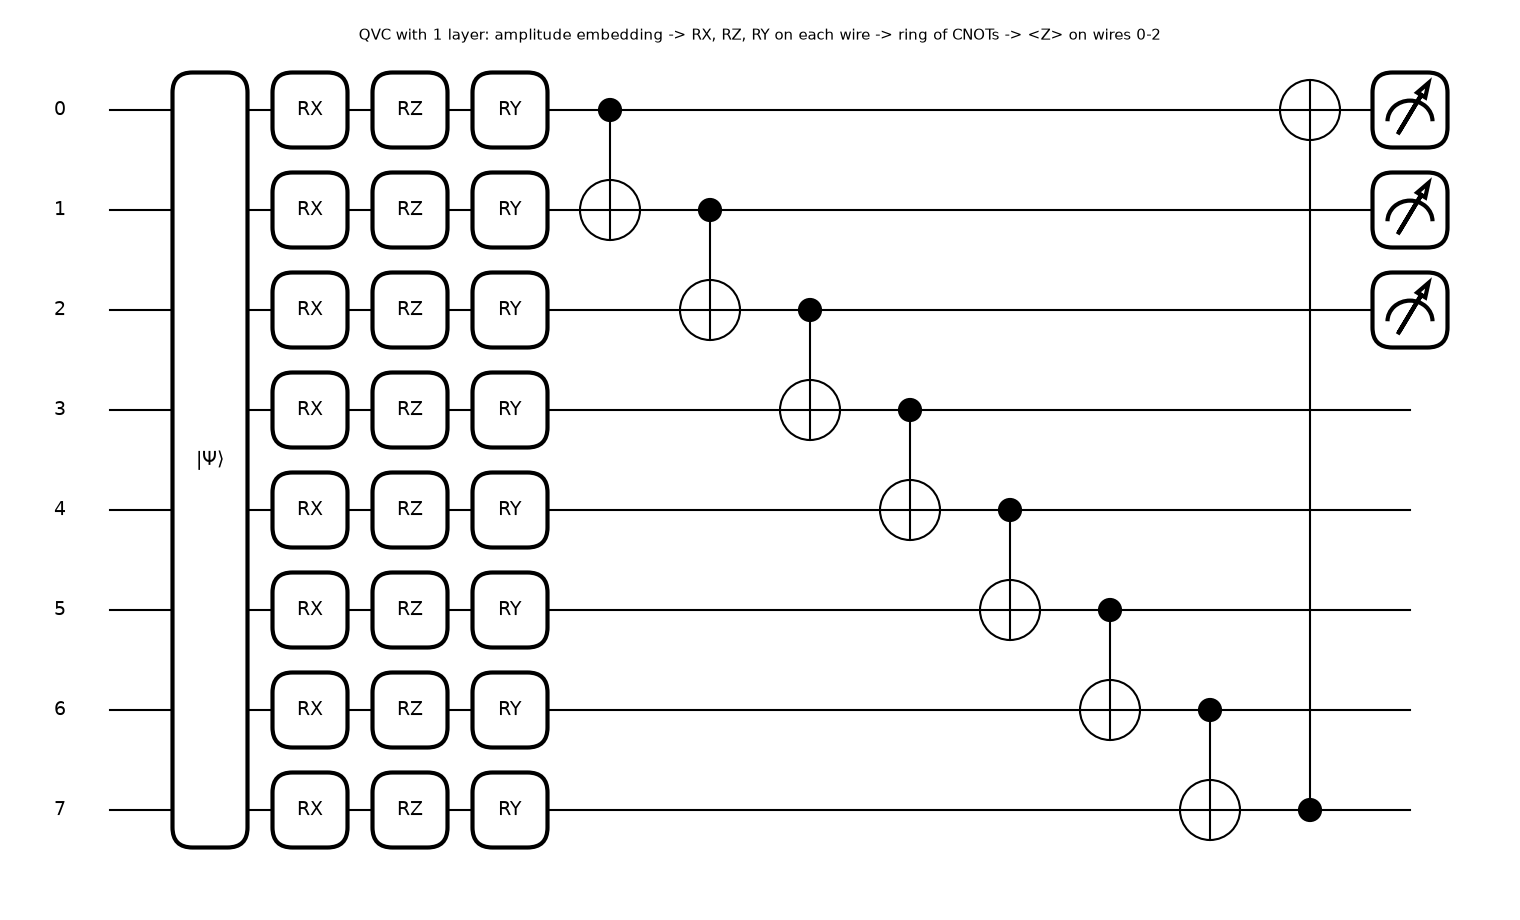

In [12]:
### one layer in full detail (the architecture of Fig. 1), drawn from the executed QNode
fig, ax = qml.draw_mpl(make_qvc_qnode(1, 3), decimals=None, level="top")(x0, np.zeros((1, 8, 3)))
fig.suptitle("QVC with 1 layer: amplitude embedding -> RX, RZ, RY on each wire -> ring of CNOTs -> <Z> on wires 0-2", fontsize=11)
plt.show()

QVC-30, layers 1-10 (the amplitude-embedding box is the first element on the left)


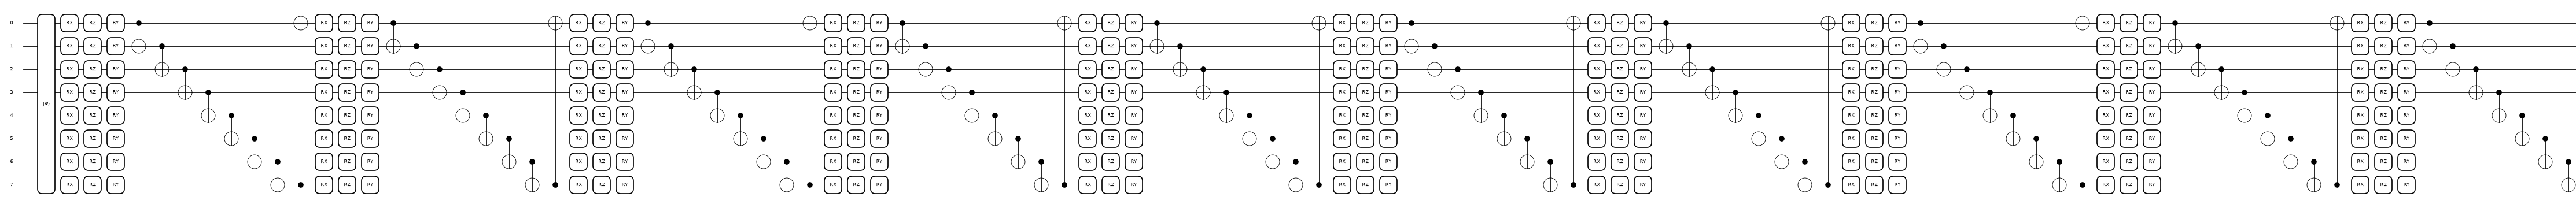

QVC-30, layers 11-20


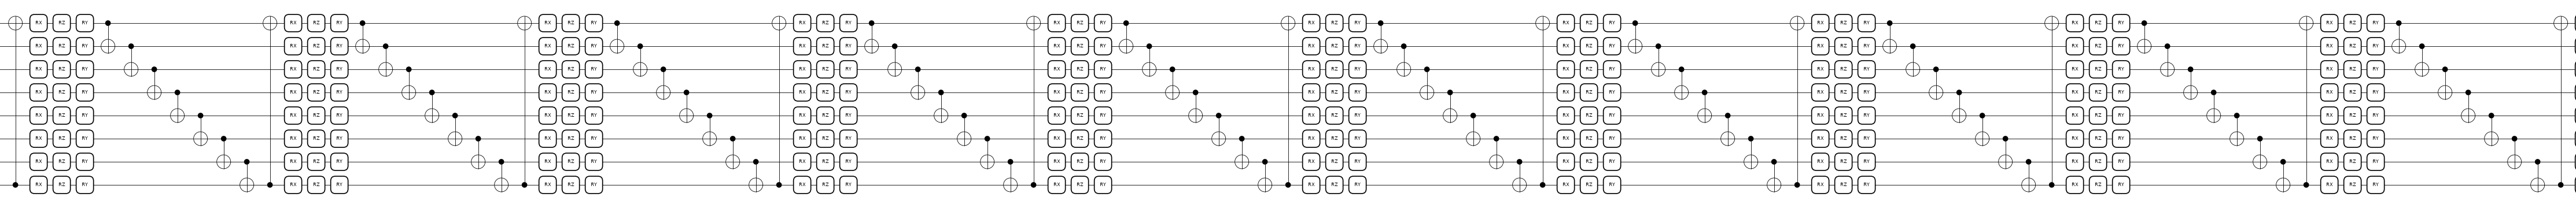

QVC-30, layers 21-30


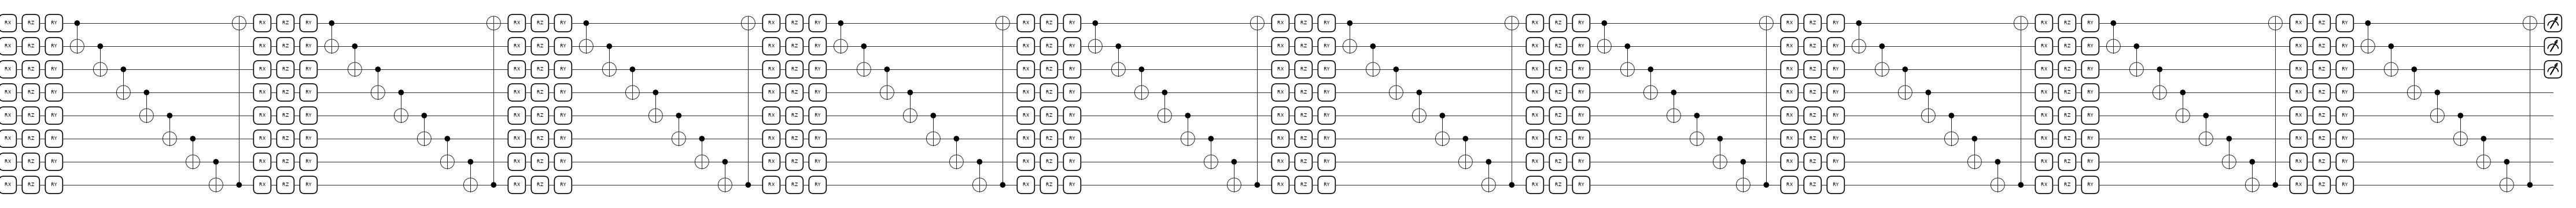

In [13]:
### the full 30-layer QVC that is trained and attacked, shown in three windows of 10 layers
import io
from IPython.display import display, Image
from matplotlib.transforms import Bbox
fig, ax = qml.draw_mpl(make_qvc_qnode(QVC_LAYERS, 3), decimals=None, level="top")(x0, np.zeros((QVC_LAYERS, 8, 3)))
Wf, Hf = fig.get_size_inches()          # one picture of the whole circuit (334 gate columns); cropped into three windows
for k in range(3):
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=40, bbox_inches=Bbox([[k * Wf / 3, 0], [(k + 1) * Wf / 3, Hf]]))
    print(f"QVC-30, layers {10 * k + 1}-{10 * k + 10}" + (" (the amplitude-embedding box is the first element on the left)" if k == 0 else ""))
    display(Image(data=buf.getvalue()))
plt.close(fig)

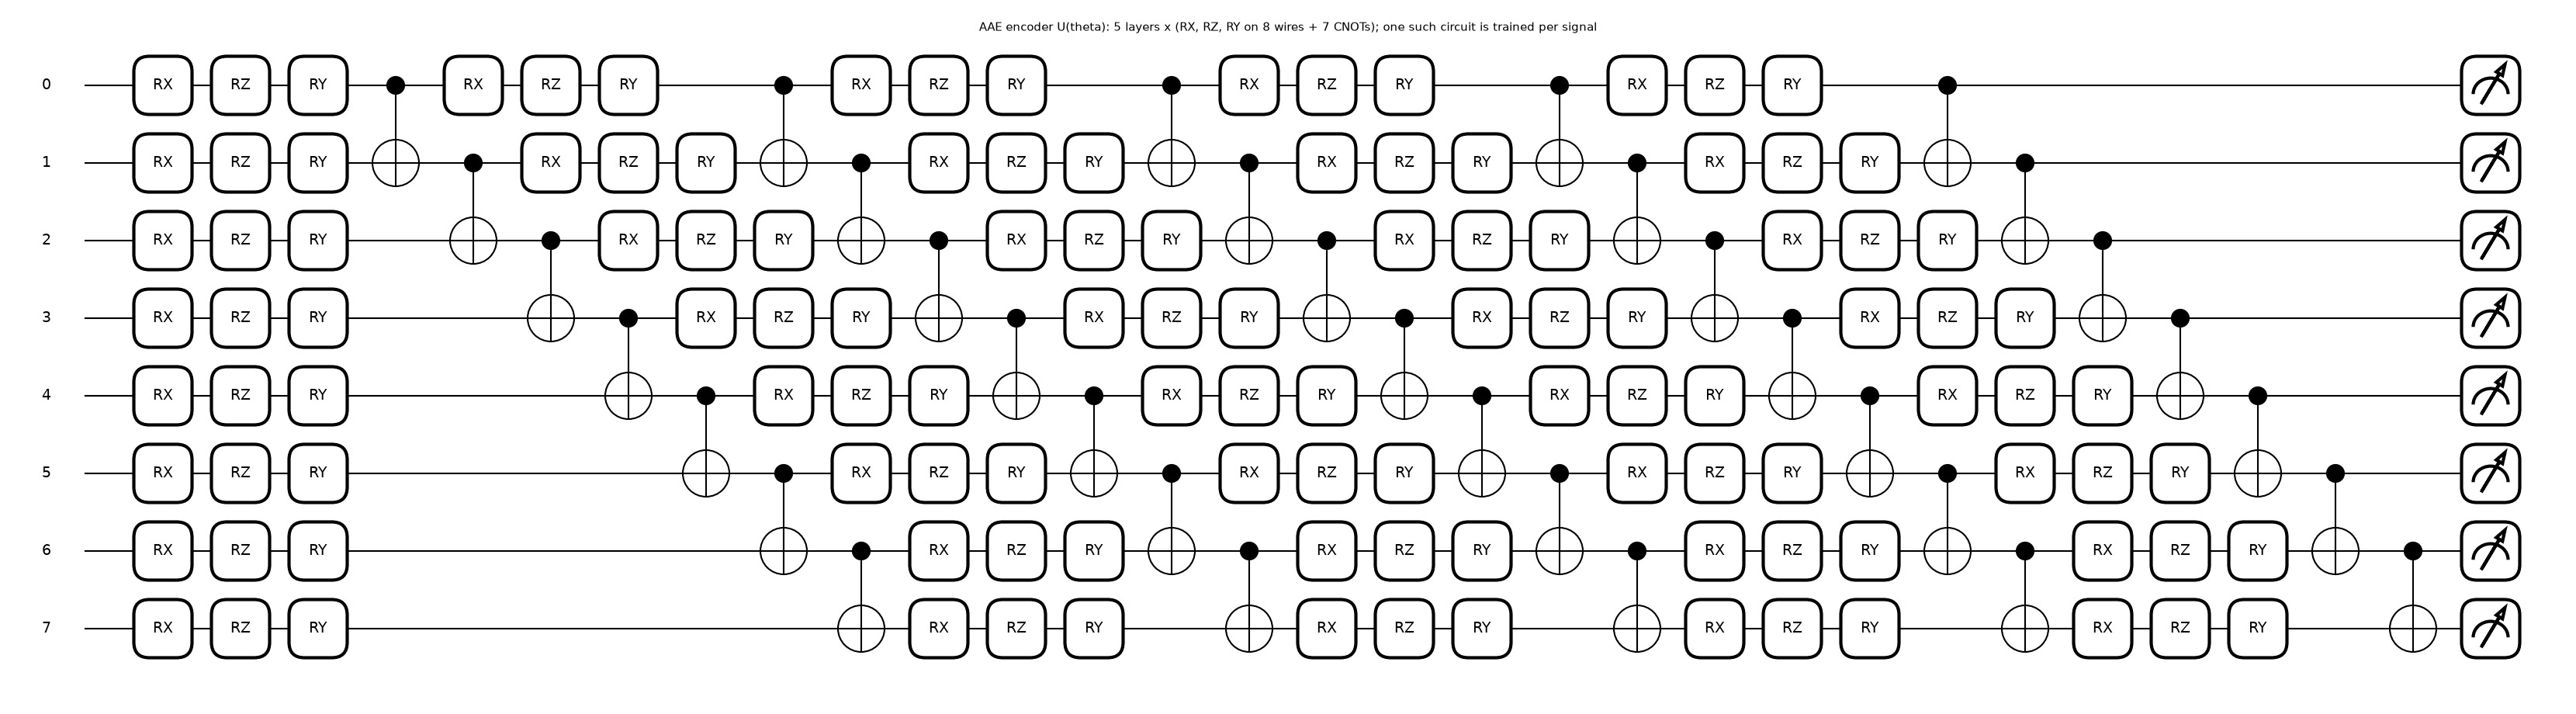

qubits 8, depth 30 | trainable angles 5 x 24 = 120 (the paper's text says 360, which does not follow from 24 angles per layer)


In [14]:
### the 5-layer approximate-amplitude-encoding circuit U(theta) (Fig. 5): it prepares the state that replaces the embedding box
fig, ax = qml.draw_mpl(make_aae_qnode(AAE_LAYERS), decimals=None, level="top")(np.zeros((AAE_LAYERS, 8, 3)))
fig.suptitle("AAE encoder U(theta): 5 layers x (RX, RZ, RY on 8 wires + 7 CNOTs); one such circuit is trained per signal", fontsize=11)
plt.show()
print("qubits 8, depth", specs_of(make_aae_qnode(AAE_LAYERS), np.zeros((AAE_LAYERS, 8, 3)))[1],
      "| trainable angles 5 x 24 = 120 (the paper's text says 360, which does not follow from 24 angles per layer)")

## 3. Models, training and the classical baselines (Table 1 and Table A3)

*CNN* (Appendix A): zero-pad the 2 x 128 I/Q image by 2 columns on each side, Conv(1 -> 32, kernel 1 x 3), ReLU, dropout 0.2,
flatten (32 x 2 x 130 = 8320), FC(16), ReLU, FC(C). *QVC-30*: 30 layers, 720 trainable angles. Both are trained with cross-entropy and
Adam (learning rates 1e-3 and 5e-3, batch size 256); the epoch with the best validation loss is kept.

*Classical baselines on identical inputs*: a random forest and an RBF-kernel SVM are trained on exactly the 256-dimensional
unit-length vectors that the QVC receives (the CNN gets the same signals divided by a fixed constant).

In [15]:
import torch.nn as nn
import torch.nn.functional as F

class QVC(nn.Module):
    """Quantum variational classifier: exact amplitude encoding (or a given state), L layers of RX-RZ-RY on every wire +
    a ring of CNOTs, then <Z_c> on the first C wires as the C logits (CHOICE: the paper does not say how outputs are read)."""
    def __init__(self, n_classes, layers=30, init_std=0.1, gen=None):
        super().__init__()
        self.C, self.layers = n_classes, layers
        self.theta = nn.Parameter(torch.randn(layers, NQ, 3, generator=gen) * init_std)
    def state_logits(self, state):
        return expz(run_layers(state, self.theta, G_RING), self.C)
    def forward(self, x):                      # x: raw signal vectors (B, 256), amplitude-encoded exactly inside
        return self.state_logits(amp_encode(x))

class CNN(nn.Module):
    """Appendix A of the paper: pad (0,2) -> Conv(1->32, 1x3) -> ReLU -> Dropout 0.2 -> Flatten -> FC16 -> ReLU -> FC(C)."""
    def __init__(self, n_classes, scale):
        super().__init__()
        self.register_buffer("scale", torch.tensor(float(scale)))   # CHOICE: fixed global input scale (train std), not per sample
        self.pad = nn.ZeroPad2d((2, 2, 0, 0))
        self.conv = nn.Conv2d(1, 32, kernel_size=(1, 3))
        self.drop = nn.Dropout(0.2)
        self.fc1 = nn.Linear(32 * 2 * 130, 16)
        self.fc2 = nn.Linear(16, n_classes)
    def forward(self, x):
        h = (x / self.scale).reshape(-1, 1, 2, 128)
        h = self.drop(F.relu(self.conv(self.pad(h))))
        return self.fc2(F.relu(self.fc1(h.flatten(1))))

def fit(model, Xtr, ytr, Xva, yva, epochs, lr, batch=256, seed=0, state_fn=None, log=None):
    """Adam + cross-entropy; keeps the parameters with the best validation loss. `state_fn` maps a batch index to model input."""
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    best, best_sd, hist = 1e9, None, []
    n = len(Xtr)
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(n, generator=g)
        for i in range(0, n, batch):
            idx = perm[i:i + batch]
            opt.zero_grad()
            loss = F.cross_entropy(model(Xtr[idx]), ytr[idx])
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            lv = F.cross_entropy(model(Xva), yva).item()
            av = (model(Xva).argmax(1) == yva).float().mean().item()
        hist.append((lv, av))
        if lv < best:
            best, best_sd = lv, {k: v.clone() for k, v in model.state_dict().items()}
        if log and (ep + 1) % log == 0:
            print(f"  epoch {ep + 1:3d}  val loss {lv:.4f}  val acc {av:.3f}")
    model.load_state_dict(best_sd)
    model.eval()
    return hist

@torch.no_grad()
def predict(model, X, bs=1000):
    return torch.cat([model(X[i:i + bs]).argmax(1) for i in range(0, len(X), bs)])

def accuracy(model, X, y):
    return (predict(model, X) == y).float().mean().item()

In [16]:
# ---- Table A3: parameter counts of the networks ----
for k, t in TASKS.items():
    n_cnn = sum(p.numel() for p in CNN(t["C"], scale=1.0).parameters())
    print(f"{k:18s}: CNN parameters {n_cnn:,}   QVC-30 trainable angles {QVC(t['C'], QVC_LAYERS).theta.numel()}")
print("paper Table A3: CNN 133,298 (binary) and 133,315 (3-class); QVC-30 1,933 gates; 5AAE-QVC-30 1,115 gates")

Binary RML        : CNN parameters 133,298   QVC-30 trainable angles 720
3-class RML       : CNN parameters 133,315   QVC-30 trainable angles 720
3-class synthetic : CNN parameters 133,315   QVC-30 trainable angles 720
paper Table A3: CNN 133,298 (binary) and 133,315 (3-class); QVC-30 1,933 gates; 5AAE-QVC-30 1,115 gates


In [17]:
MODELS, TRAIN_LOG = {}, {}
for k, t in TASKS.items():
    torch.manual_seed(SEED)
    cnn = CNN(t["C"], scale=t["scale"])
    t0 = time.time()
    h_cnn = fit(cnn, t["Xtr"], t["ytr"], t["Xva"], t["yva"], epochs=CNN_EPOCHS, lr=CNN_LR, batch=QVC_BATCH, seed=SEED)
    t_cnn = time.time() - t0
    torch.manual_seed(SEED)
    qvc = QVC(t["C"], QVC_LAYERS, init_std=0.1)               # CHOICE: small starting angles (best validation loss in a pilot)
    t0 = time.time()
    h_qvc = fit(qvc, t["Xtr"], t["ytr"], t["Xva"], t["yva"], epochs=QVC_EPOCHS, lr=QVC_LR, batch=QVC_BATCH, seed=SEED)
    t_qvc = time.time() - t0
    MODELS[k] = dict(cnn=cnn, qvc=qvc)
    TRAIN_LOG[k] = dict(cnn=h_cnn, qvc=h_qvc, t_cnn=t_cnn, t_qvc=t_qvc)
    print(f"{k:18s} CNN test acc {accuracy(cnn, t['Xte'], t['yte']):.3f} ({t_cnn:5.0f} s) | "
          f"QVC-30 test acc {accuracy(qvc, t['Xte'], t['yte']):.3f} ({t_qvc:5.0f} s)")

Binary RML         CNN test acc 0.940 (   74 s) | QVC-30 test acc 0.883 (   86 s)


3-class RML        CNN test acc 0.878 (   63 s) | QVC-30 test acc 0.651 (  138 s)


3-class synthetic  CNN test acc 0.920 (   91 s) | QVC-30 test acc 0.360 (  184 s)


In [18]:
CLASSICAL = {}
def l2(a): return a / np.linalg.norm(a, axis=1, keepdims=True)
for k, t in TASKS.items():
    accs = {"RandomForest": [], "SVC (rbf)": []}
    for s in SEEDS_CLASSICAL:                                   # different splits, same sizes -> mean +- std
        tt = make_task(k, t["Xall"], t["yall"], t["classes"], s)
        Xa, ya = np.concatenate([tt["Xtr"].numpy(), tt["Xva"].numpy()]), np.concatenate([tt["ytr"].numpy(), tt["yva"].numpy()])
        rf = RandomForestClassifier(n_estimators=300, random_state=s, n_jobs=1).fit(l2(Xa), ya)
        sv = SVC(kernel="rbf", C=10.0, gamma="scale", random_state=s).fit(l2(Xa), ya)   # CHOICE: C = 10 (not tuned on test data)
        accs["RandomForest"].append(rf.score(l2(tt["Xte"].numpy()), tt["yte"].numpy()))
        accs["SVC (rbf)"].append(sv.score(l2(tt["Xte"].numpy()), tt["yte"].numpy()))
        if s == SEED:
            CLASSICAL[k] = dict(rf=rf, svc=sv)
    CLASSICAL[k]["acc"] = {m: (float(np.mean(v)), float(np.std(v))) for m, v in accs.items()}
    print(f"{k:18s} " + "  ".join(f"{m} {np.mean(v):.3f} +- {np.std(v):.3f}" for m, v in accs.items()), f"(over {len(SEEDS_CLASSICAL)} split seeds)")

Binary RML         RandomForest 0.997 +- 0.000  SVC (rbf) 0.990 +- 0.000 (over 1 split seeds)


3-class RML        RandomForest 0.909 +- 0.000  SVC (rbf) 0.749 +- 0.000 (over 1 split seeds)


3-class synthetic  RandomForest 1.000 +- 0.000  SVC (rbf) 0.931 +- 0.000 (over 1 split seeds)


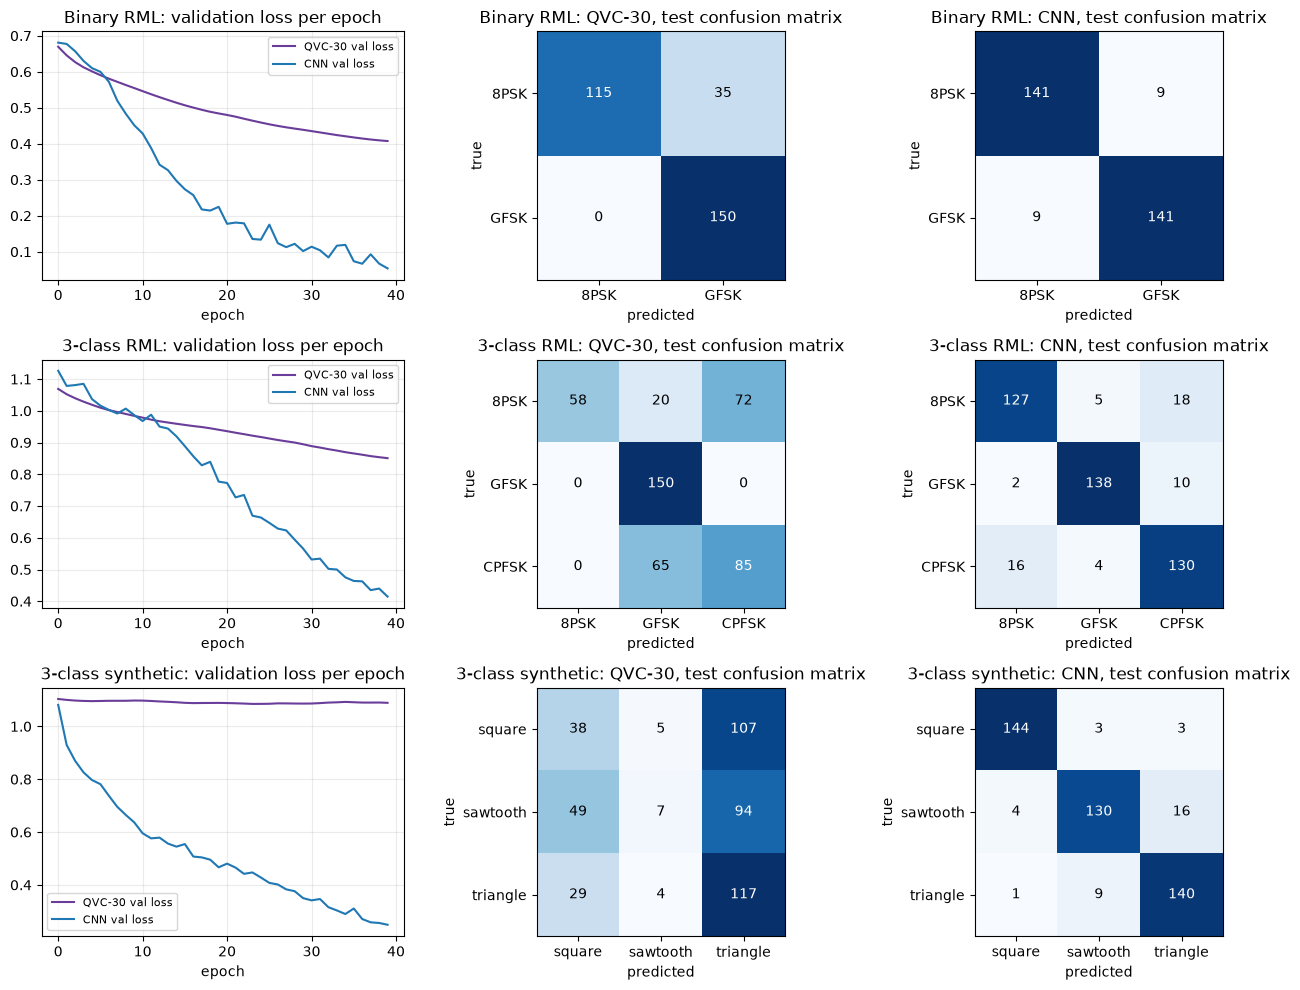

In [19]:
fig, axs = plt.subplots(3, 3, figsize=(13, 10))
for r, (k, t) in enumerate(TASKS.items()):
    h = TRAIN_LOG[k]
    axs[r, 0].plot([a for a, _ in h["qvc"]], color=COL["QVC"], label="QVC-30 val loss")
    axs[r, 0].plot([a for a, _ in h["cnn"]], color=COL["CNN"], label="CNN val loss")
    axs[r, 0].set_title(f"{k}: validation loss per epoch"); axs[r, 0].set_xlabel("epoch"); axs[r, 0].legend(fontsize=8)
    for j, (nm, mdl) in enumerate([("QVC-30", MODELS[k]["qvc"]), ("CNN", MODELS[k]["cnn"])]):
        cm = confusion_matrix(t["yte"].numpy(), predict(mdl, t["Xte"]).numpy())
        ax = axs[r, 1 + j]; ax.imshow(cm, cmap="Blues"); ax.grid(False)
        ax.set_xticks(range(t["C"])); ax.set_xticklabels(t["classes"]); ax.set_yticks(range(t["C"])); ax.set_yticklabels(t["classes"])
        for a in range(t["C"]):
            for b in range(t["C"]): ax.text(b, a, cm[a, b], ha="center", va="center", color="black" if cm[a, b] < cm.max() / 2 else "white")
        ax.set_title(f"{k}: {nm}, test confusion matrix"); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.show()

## 4. Adversarial attacks on the QVC and the CNN

An attacker adds a small perturbation to a received signal x so that the classifier changes its answer. The attack strength is the
**perturbation-to-signal ratio** PSR = 10 log10(P_perturbation / P_signal) (dB); 0 dB means the perturbation is as strong as the
signal itself.

- **FGSM**: x + eps sign(grad_x loss), one gradient step (Goodfellow et al.).
- **PGD**: random start inside the L-infinity ball, ten signed-gradient steps of size 2.5 eps / 10, projection back onto the ball
  (Madry et al.). The L-infinity budget of a signal is eps = rms(x) 10^(PSR/20), which gives a perturbation power of exactly eps^2,
  i.e. the stated PSR.
- **UAP** (Sadeghi and Larsson, Algorithm 1): one input-agnostic perturbation. The adversary collects a subset of training signals,
  normalises their loss gradients, takes the first principal component v1 of that matrix and uses r = p_max v1 for *every* signal.

**White-box**: the gradient comes from the attacked model. **Black-box**: the adversarial signals are crafted on the *other* model
(the substitute) and fed to the victim. The QVC is simulated exactly, so the gradients are exact, which is the strongest possible
white-box setting for it.

Because a model that is only *hard to attack with cross-entropy gradients* is not the same as a robust model, the notebook adds
checks that the paper does not report (Section 5): a margin-loss PGD (a different objective), random restarts, the worst case over
all attacks per signal, a random-noise control at the same PSR, and transfer to a random forest and an SVM.

In [20]:
def psr_eps(X, psr_db):
    """Per-signal L-infinity budget whose perturbation-to-signal power ratio is psr_db: PSR = 10 log10(P_pert / P_signal),
    P = mean squared amplitude. A perturbation eps * sign(.) has power eps^2, so eps = rms(x) * 10^(PSR/20)."""
    rms = X.pow(2).mean(1, keepdim=True).sqrt()
    return rms * 10.0 ** (psr_db / 20.0)

def attack_loss(logits, y, kind):
    if kind == "ce":
        return F.cross_entropy(logits, y, reduction="sum")
    other = logits.masked_fill(F.one_hot(y, logits.shape[1]).bool(), -1e9).max(1).values   # best wrong class
    return (other - logits.gather(1, y[:, None])[:, 0]).sum()                              # CW-style margin, to be maximised

def input_grad(model, X, y, kind="ce", bs=300):
    """Exact gradient of the attack loss with respect to the raw signal vectors."""
    out = []
    for i in range(0, len(X), bs):
        x = X[i:i + bs].clone().requires_grad_(True)
        g, = torch.autograd.grad(attack_loss(model(x), y[i:i + bs], kind), x)
        out.append(g)
    return torch.cat(out)

def fgsm(model, X, y, psr_db, kind="ce"):
    return X + psr_eps(X, psr_db) * input_grad(model, X, y, kind).sign()

def pgd(model, X, y, psr_db, steps=10, kind="ce", restarts=1, seed=0):
    """Madry et al.: random start inside the L-infinity ball, `steps` signed-gradient steps of size 2.5 eps / steps,
    projection onto the ball. With restarts, the first restart that fools the model is kept for every signal."""
    eps = psr_eps(X, psr_db)
    gen = torch.Generator().manual_seed(seed)
    best, fooled = X.clone(), torch.zeros(len(X), dtype=torch.bool)
    for r in range(restarts):
        xa = X + (torch.rand(X.shape, generator=gen) * 2 - 1) * eps
        for _ in range(steps):
            xa = xa + (2.5 * eps / steps) * input_grad(model, xa, y, kind).sign()
            xa = X + torch.max(torch.min(xa - X, eps), -eps)
        with torch.no_grad():
            wrong = predict(model, xa) != y
        take = wrong & ~fooled
        best[take] = xa[take]
        best[~fooled & ~wrong] = xa[~fooled & ~wrong]      # keep the latest try for still-unfooled signals
        fooled |= wrong
    return best

def uap(model, X_sub, y_sub, psr_db, mean_power):
    """Sadeghi and Larsson (Algorithm 1): normalised loss gradients of a subset, first principal component v1, r = p_max v1."""
    g = input_grad(model, X_sub, y_sub, "ce")
    n = g / g.norm(dim=1, keepdim=True).clamp_min(1e-12)
    _, _, Vh = torch.linalg.svd(n, full_matrices=False)
    v1 = Vh[0]
    if (n @ v1).sum() < 0:                                  # the sign of a principal component is arbitrary: point it up the loss
        v1 = -v1
    p_max = (X_sub.shape[1] * mean_power * 10.0 ** (psr_db / 10.0)) ** 0.5
    return p_max * v1

def power_ratio_db(X, Xadv):
    return (10 * torch.log10((Xadv - X).pow(2).mean(1) / X.pow(2).mean(1).clamp_min(1e-30))).mean().item()

In [21]:
def att_idx(t):
    g = torch.Generator().manual_seed(SEED)
    return torch.randperm(len(t["Xte"]), generator=g)[:N_ATTACK]

WB, ADV = {}, {}        # WB[(task, model, attack, psr)] -> per-signal correctness; ADV[(task, source, attack, psr)] -> crafted signals
def correct_vec(model, X, y):
    return predict(model, X) == y

def craft_and_score(task, mname, model, psr, attacks=("FGSM", "PGD", "UAP", "noise")):
    t = TASKS[task]; ix = att_idx(t)
    X, y = t["Xte"][ix], t["yte"][ix]
    out = {}
    if "FGSM" in attacks:  out["FGSM"] = fgsm(model, X, y, psr)
    if "PGD" in attacks:   out["PGD"] = pgd(model, X, y, psr, steps=PGD_STEPS, seed=SEED)
    if "UAP" in attacks:
        Xs_, ys_ = t["Xtr"][:UAP_SUBSET], t["ytr"][:UAP_SUBSET]
        r = uap(model, Xs_, ys_, psr, mean_power=Xs_.pow(2).mean().item())
        out["UAP"] = X + r
    if "noise" in attacks:
        g = torch.Generator().manual_seed(SEED)
        out["noise"] = X + psr_eps(X, psr) * torch.sign(torch.randn(X.shape, generator=g))
    if "PGD-margin" in attacks:    out["PGD-margin"] = pgd(model, X, y, psr, steps=PGD_STEPS, kind="margin", seed=SEED)
    if "PGD-restarts" in attacks:  out["PGD-restarts"] = pgd(model, X, y, psr, steps=PGD_STEPS, restarts=PGD_RESTARTS, seed=SEED + 1)
    for a, Xa in out.items():
        ADV[(task, mname, a, psr)] = Xa
        WB[(task, mname, a, psr)] = correct_vec(model, Xa, y).numpy()
    return out

t0 = time.time()
for task, t in TASKS.items():
    ix = att_idx(t)
    for mname in ["QVC", "CNN"]:
        model = MODELS[task]["qvc" if mname == "QVC" else "cnn"]
        WB[(task, mname, "clean", None)] = correct_vec(model, t["Xte"][ix], t["yte"][ix]).numpy()
        for psr in PSR_GRID:
            craft_and_score(task, mname, model, psr)
        for psr in ADAPT_LEVELS:
            craft_and_score(task, mname, model, psr, attacks=("PGD-margin", "PGD-restarts"))
    print(f"{task:18s} white-box attacks done ({time.time() - t0:.0f} s so far)")

# sanity check of the PSR definition: the realised perturbation-to-signal ratio of every attack
t = TASKS["3-class RML"]; ix = att_idx(t)
for a in ["FGSM", "PGD", "UAP"]:
    print(f"{a:5s} requested -24 dB, realised {power_ratio_db(t['Xte'][ix], ADV[('3-class RML', 'QVC', a, -24)]):6.1f} dB (QVC), "
          f"{power_ratio_db(t['Xte'][ix], ADV[('3-class RML', 'CNN', a, -24)]):6.1f} dB (CNN)")

Binary RML         white-box attacks done (57 s so far)


3-class RML        white-box attacks done (115 s so far)


3-class synthetic  white-box attacks done (174 s so far)
FGSM  requested -24 dB, realised  -24.0 dB (QVC),   -inf dB (CNN)
PGD   requested -24 dB, realised  -24.0 dB (QVC),  -24.6 dB (CNN)
UAP   requested -24 dB, realised  -23.8 dB (QVC),  -23.8 dB (CNN)


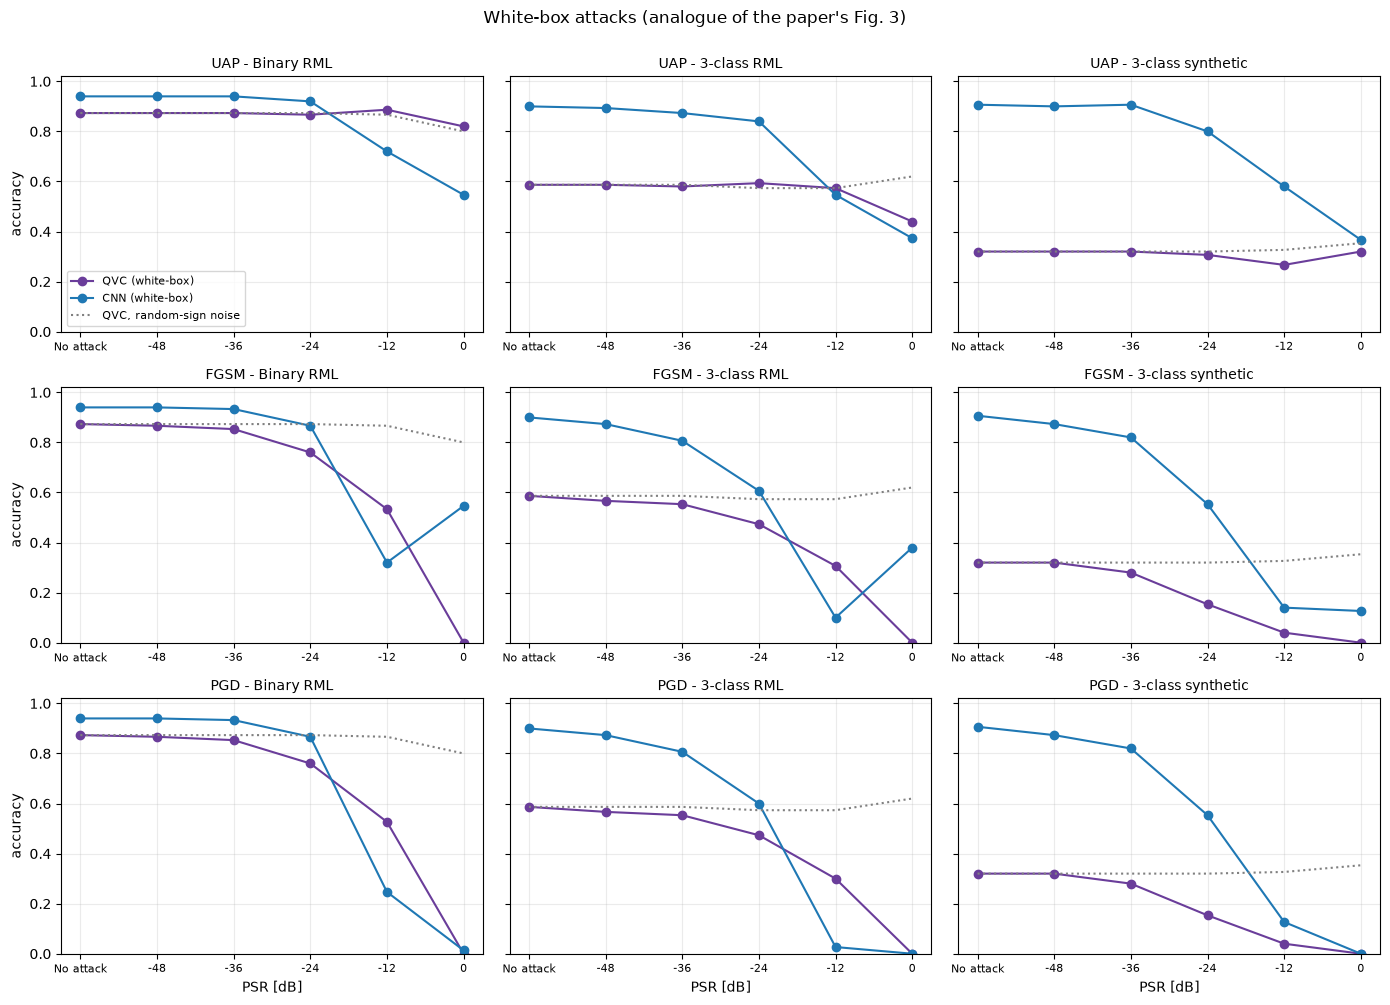

In [22]:
def acc_of(key): return float(np.mean(WB[key]))
fig, axs = plt.subplots(3, 3, figsize=(14, 10), sharey=True)
xs = list(range(len(PSR_GRID) + 1))
for r, a in enumerate(["UAP", "FGSM", "PGD"]):
    for c, task in enumerate(TASKS):
        ax = axs[r, c]
        for mname in ["QVC", "CNN"]:
            ys_ = [acc_of((task, mname, "clean", None))] + [acc_of((task, mname, a, p)) for p in PSR_GRID]
            ax.plot(xs, ys_, "o-", color=COL[mname], label=f"{mname} (white-box)")
        ys_ = [acc_of((task, "QVC", "clean", None))] + [acc_of((task, "QVC", "noise", p)) for p in PSR_GRID]
        ax.plot(xs, ys_, ":", color="gray", label="QVC, random-sign noise")
        ax.set_xticks(xs); ax.set_xticklabels(["No attack"] + [str(p) for p in PSR_GRID], fontsize=8)
        ax.set_title(f"{a} - {task}", fontsize=10); ax.set_ylim(0, 1.02)
        if c == 0: ax.set_ylabel("accuracy")
        if r == 2: ax.set_xlabel("PSR [dB]")
        if r == 0 and c == 0: ax.legend(fontsize=8)
plt.suptitle("White-box attacks (analogue of the paper's Fig. 3)", y=1.0)
plt.tight_layout(); plt.show()

## 5. Is the robustness real? Gradient-masking and insensitivity checks

A classifier can look robust against an attack because the attack is weak for it (flat or saturated gradients, a loss surface the
chosen objective cannot climb) or because it simply ignores the part of the input the attack changes. The paper does not test
either. The table below compares, at the strongest levels of the adaptive grid:

- the clean accuracy and the accuracy under **random-sign noise** of the same PSR (a non-adversarial control);
- **FGSM**, **PGD** (cross-entropy), **PGD with the margin loss** (best wrong logit minus true logit) and **PGD with random restarts**;
- the **worst case per signal** over all of these white-box attacks;
- the **black-box** accuracy under the PGD signals crafted on the other model.

Indicators of gradient masking (Athalye et al.): an iterative attack weaker than a one-step attack; a margin attack much stronger
than cross-entropy; black-box attacks stronger than white-box ones; accuracy that does not fall to chance when the budget grows.
Gradients that vanish on clean inputs are counted too.

In [23]:
rows = []
for task, t in TASKS.items():
    for mname in ["QVC", "CNN"]:
        other = "CNN" if mname == "QVC" else "QVC"
        for psr in ADAPT_LEVELS:
            names = ["FGSM", "PGD", "PGD-margin", "PGD-restarts"]
            worst = np.all([WB[(task, mname, a, psr)] for a in names], axis=0).mean()
            ix = att_idx(t)
            victim = MODELS[task]["qvc" if mname == "QVC" else "cnn"]
            bb = float(np.mean(correct_vec(victim, ADV[(task, other, "PGD", psr)], t["yte"][ix]).numpy()))
            rows.append(dict(task=task, model=mname, PSR=psr, clean=acc_of((task, mname, "clean", None)),
                             noise=acc_of((task, mname, "noise", psr)), FGSM=acc_of((task, mname, "FGSM", psr)),
                             PGD=acc_of((task, mname, "PGD", psr)), PGD_margin=acc_of((task, mname, "PGD-margin", psr)),
                             PGD_restarts=acc_of((task, mname, "PGD-restarts", psr)), worst_case=worst,
                             black_box_PGD_from_other=bb))
GM = pd.DataFrame(rows).round(3)
print(GM.to_string(index=False))

# gradient statistics on clean test signals
print("\nCE-gradient size on clean test signals (relative to the signal norm):")
for task, t in TASKS.items():
    ix = att_idx(t)
    for mname in ["QVC", "CNN"]:
        g = input_grad(MODELS[task]["qvc" if mname == "QVC" else "cnn"], t["Xte"][ix], t["yte"][ix], "ce")
        rel = (g.norm(dim=1) * t["Xte"][ix].norm(dim=1)).numpy()
        print(f"  {task:18s} {mname}: median |g||x| = {np.median(rel):.3e}, share of exactly-zero gradients {(g.norm(dim=1) == 0).float().mean():.3f}")

flags = []
for _, r in GM.iterrows():
    if r.PGD > r.FGSM + 0.02: flags.append(f"{r.task}/{r.model}/{r.PSR}: PGD weaker than FGSM")
    if r.PGD - r.PGD_margin > 0.05: flags.append(f"{r.task}/{r.model}/{r.PSR}: margin attack much stronger than CE ({r.PGD:.2f} -> {r.PGD_margin:.2f})")
    if r.black_box_PGD_from_other + 0.02 < r.worst_case: flags.append(f"{r.task}/{r.model}/{r.PSR}: transfer beats the white-box attacks")
GM_FLAGS = flags
print("\nGradient-masking indicators triggered:", len(flags))
for f_ in flags: print("  -", f_)

             task model  PSR  clean  noise  FGSM   PGD  PGD_margin  PGD_restarts  worst_case  black_box_PGD_from_other
       Binary RML   QVC  -24  0.873  0.873 0.760 0.760       0.760         0.760       0.760                     0.847
       Binary RML   QVC  -12  0.873  0.867 0.533 0.527       0.527         0.527       0.527                     0.740
       Binary RML   CNN  -24  0.940  0.933 0.867 0.867       0.867         0.867       0.867                     0.927
       Binary RML   CNN  -12  0.940  0.800 0.320 0.247       0.247         0.240       0.240                     0.820
      3-class RML   QVC  -24  0.587  0.573 0.473 0.473       0.467         0.473       0.467                     0.567
      3-class RML   QVC  -12  0.587  0.573 0.307 0.300       0.287         0.300       0.287                     0.553
      3-class RML   CNN  -24  0.900  0.907 0.607 0.600       0.600         0.600       0.593                     0.880
      3-class RML   CNN  -12  0.900  0.460 0.100

  Binary RML         QVC: median |g||x| = 9.295e-01, share of exactly-zero gradients 0.000
  Binary RML         CNN: median |g||x| = 5.088e-01, share of exactly-zero gradients 0.000


  3-class RML        QVC: median |g||x| = 1.269e+00, share of exactly-zero gradients 0.000
  3-class RML        CNN: median |g||x| = 4.143e+00, share of exactly-zero gradients 0.053


  3-class synthetic  QVC: median |g||x| = 1.197e+00, share of exactly-zero gradients 0.000
  3-class synthetic  CNN: median |g||x| = 4.443e+00, share of exactly-zero gradients 0.000

Gradient-masking indicators triggered: 0


## 6. Black-box attacks: transfer between the quantum and the classical model (RQ1)

The adversarial signals crafted on one model in Section 4 are now fed to the other one. The paper's central observation is
asymmetric: attacks crafted on the QVC fool the CNN, while attacks crafted on the CNN barely move the QVC. Two extra victims
(a random forest and an SVM on the same unit-length inputs) show whether the QVC's resistance is special or simply what any
model that was not the attack's source does.

In [24]:
def victim_acc(task, victim, Xadv):
    t = TASKS[task]; y = t["yte"][att_idx(t)]
    if victim in ("QVC", "CNN"):
        return float(correct_vec(MODELS[task]["qvc" if victim == "QVC" else "cnn"], Xadv, y).float().mean())
    clf = CLASSICAL[task]["rf" if victim == "RF" else "svc"]
    return float((clf.predict(l2(Xadv.numpy())) == y.numpy()).mean())

BB = {}     # BB[(task, source, victim, attack, psr)] -> accuracy
for task in TASKS:
    for src in ["QVC", "CNN"]:
        for a in ["FGSM", "PGD", "UAP", "noise"]:
            for psr in PSR_GRID:
                for victim in ["QVC", "CNN", "RF", "SVC"]:
                    BB[(task, src, victim, a, psr)] = victim_acc(task, victim, ADV[(task, src, a, psr)])
rows = []
lv = ADAPT_LEVELS[-1]
for task in TASKS:
    t = TASKS[task]; ix = att_idx(t)
    row = dict(task=task, PSR=lv, attack="PGD")
    for victim in ["QVC", "CNN", "RF", "SVC"]:
        row[f"clean {victim}"] = victim_acc(task, victim, t["Xte"][ix])
    for src in ["QVC", "CNN"]:
        for victim in ["QVC", "CNN", "RF", "SVC"]:
            if victim != src:
                row[f"{src}-crafted -> {victim}"] = BB[(task, src, victim, "PGD", lv)]
    rows.append(row)
print(f"PGD at PSR = {lv} dB: accuracy of every victim (columns 'X-crafted -> Y' are black-box)")
print(pd.DataFrame(rows).round(3).T.to_string(header=False))

PGD at PSR = -12 dB: accuracy of every victim (columns 'X-crafted -> Y' are black-box)
task                Binary RML  3-class RML  3-class synthetic
PSR                        -12          -12                -12
attack                     PGD          PGD                PGD
clean QVC                0.873        0.587               0.32
clean CNN                 0.94          0.9              0.907
clean RF                 0.993        0.893                1.0
clean SVC                0.993          0.7              0.947
QVC-crafted -> CNN        0.82         0.68              0.707
QVC-crafted -> RF         0.54        0.453              0.933
QVC-crafted -> SVC        0.92        0.567               0.88
CNN-crafted -> QVC        0.74        0.553               0.32
CNN-crafted -> RF         0.54        0.373              0.947
CNN-crafted -> SVC       0.973        0.633               0.74


## 7. Approximate amplitude encoding (AAE, RQ3)

Exact amplitude encoding needs about a thousand gates for 8 qubits. The AAE replaces it by a shallow circuit U(theta) of 5 layers
(155 gates) whose angles are trained **for each signal separately** so that U(theta)|0> is close to the exact encoded state; the
quality is the fidelity F = |<psi_exact|psi_approx>|^2. The paper trains the inverse circuit to map the exact state to |0>; that
maximises the very same overlap, so the circuit is trained directly here (Adam, step 0.1, betas 0.9 / 0.99, 300 iterations). The
global phase of the approximate state is kept, as in the paper (it does not influence the Pauli-Z read-out).

Every signal needs its own optimisation, which is the expensive part of this notebook (about 0.2 s per signal and 300 iterations
on one CPU thread, so subsets are used, see the configuration cell). The sensitivity cell shows how much the start angles matter.

In [25]:
def aae_encode(x, layers=5, iters=300, lr=0.1, seed=0, theta0=None, chunk=1000, init="uniform"):
    """Approximate amplitude encoding of real vectors x (N, 256): for every signal a shallow circuit U(theta) of `layers`
    layers (RX, RZ, RY on each wire + open CNOT chain) is trained so that U(theta)|0> is as close as possible to the exact
    amplitude-encoded state. Training the inverse circuit to reach |0> (the paper) maximises the same overlap
    |<0|U^-1|psi>|^2 = |<psi|U|0>|^2, so the circuit is trained directly here (Adam, lr 0.1, betas 0.9/0.99, eps 1e-8).
    Returns (states (N, 256) complex, fidelity (N,), theta (N, layers, 8, 3)). `theta0` warm-starts the angles."""
    psi_all = amp_encode(torch.as_tensor(x))
    gen = torch.Generator().manual_seed(seed)
    states, fids, thetas = [], [], []
    for a in range(0, len(psi_all), chunk):
        psi = psi_all[a:a + chunk]
        n = len(psi)
        if theta0 is not None:
            th = theta0[a:a + chunk].clone()
        else:   # CHOICE: the paper gives no starting angles; uniform in [0, 2 pi) lands at the paper's fidelity (see pilot)
            th = (torch.rand(n, layers, NQ, 3, generator=gen) * 2 * np.pi if init == "uniform"
                  else torch.randn(n, layers, NQ, 3, generator=gen) * float(init))
        th.requires_grad_(True)
        opt = torch.optim.Adam([th], lr=lr, betas=(0.9, 0.99), eps=1e-8)
        s0 = zero_state(n)
        for _ in range(iters):
            opt.zero_grad()
            out = run_layers(s0, th, G_CHAIN)
            fid = (psi.conj() * out).sum(1).abs() ** 2
            (1 - fid).sum().backward()                          # samples are independent and Adam is element-wise
            opt.step()
        with torch.no_grad():
            out = run_layers(s0, th, G_CHAIN)
            fids.append((psi.conj() * out).sum(1).abs() ** 2)
            states.append(out)
            thetas.append(th.detach())
    return torch.cat(states), torch.cat(fids), torch.cat(thetas)

In [26]:
# fidelity of the 5-layer encoder: repeats and sensitivity to the starting angles (claim: 0.8957 +- 0.0003)
t3 = TASKS["3-class RML"]
g_ = torch.Generator().manual_seed(SEED)
sel = torch.randperm(len(t3["Xte"]), generator=g_)[:FID_N]
t0 = time.time()
rep_means = []
for rep in range(FID_REPEATS):
    _, f_, _ = aae_encode(t3["Xte"][sel], AAE_LAYERS, AAE_ITERS, AAE_LR, seed=SEED + rep)
    rep_means.append(f_.mean().item())
FID_MEAN, FID_STD = float(np.mean(rep_means)), float(np.std(rep_means))
print(f"5-layer AAE, {FID_N} real 3-class signals x {FID_REPEATS} repetitions ({AAE_ITERS} Adam iterations): "
      f"mean fidelity {FID_MEAN:.4f} +- {FID_STD:.4f}  (paper 0.8957 +- 0.0003)  [{time.time() - t0:.0f} s]")
sens = {}
for name, init in [("N(0, 0.1^2)", 0.1), ("N(0, 1)", 1.0), ("uniform [0, 2pi)", "uniform")]:
    _, f_, _ = aae_encode(t3["Xte"][sel[:min(FID_N, 24)]], AAE_LAYERS, AAE_ITERS, AAE_LR, seed=SEED, init=init)
    sens[name] = f_.mean().item()
print("sensitivity to the starting angles (mean fidelity):", {k: round(v, 3) for k, v in sens.items()})

5-layer AAE, 12 real 3-class signals x 3 repetitions (60 Adam iterations): mean fidelity 0.7900 +- 0.0164  (paper 0.8957 +- 0.0003)  [16 s]


sensitivity to the starting angles (mean fidelity): {'N(0, 0.1^2)': 0.912, 'N(0, 1)': 0.796, 'uniform [0, 2pi)': 0.804}


In [27]:
class AsStates(nn.Module):
    """Wraps a QVC so that it takes a batch of (approximately) encoded states instead of raw signals."""
    def __init__(self, qvc):
        super().__init__(); self.qvc = qvc
    def forward(self, s): return self.qvc.state_logits(s)

import copy
def finetune_on_states(base_qvc, S, y, epochs, seed):
    """CHOICE: the AAE-QVC starts from the trained QVC-30 and is fine-tuned on the approximate states (compute budget)."""
    q = copy.deepcopy(base_qvc)
    n_va = max(len(S) // 10, 3)
    g = torch.Generator().manual_seed(seed); perm = torch.randperm(len(S), generator=g)
    va, tr = perm[:n_va], perm[n_va:]
    fit(AsStates(q), S[tr], y[tr], S[va], y[va], epochs=epochs, lr=QVC_LR, batch=QVC_BATCH, seed=seed)
    return q

AAE, AAE_MODELS = {}, {}
t0 = time.time()
for task, t in TASKS.items():
    C = t["C"]
    tr_idx = torch.cat([torch.where(t["ytr"] == c)[0][:AAE_TRAIN_PER_CLASS] for c in range(C)])
    te_idx = att_idx(t)[:AAE_TEST_PER_CLASS * C]                       # a random subset of the attacked test signals
    S_tr, f_tr, th_tr = aae_encode(t["Xtr"][tr_idx], AAE_LAYERS, AAE_ITERS, AAE_LR, seed=SEED)
    S_te, f_te, th_te = aae_encode(t["Xte"][te_idx], AAE_LAYERS, AAE_ITERS, AAE_LR, seed=SEED + 1)
    q_aae = finetune_on_states(MODELS[task]["qvc"], S_tr, t["ytr"][tr_idx], AAE_FT_EPOCHS, SEED)
    AAE[task] = dict(tr_idx=tr_idx, te_idx=te_idx, S_tr=S_tr, th_tr=th_tr, S_te=S_te, th_te=th_te, f_tr=f_tr, f_te=f_te)
    AAE_MODELS[task] = q_aae
    print(f"{task:18s} AAE fidelity train {f_tr.mean():.3f} / test {f_te.mean():.3f}  (min {f_te.min():.2f})  [{time.time() - t0:.0f} s]")

Binary RML         AAE fidelity train 0.809 / test 0.805  (min 0.48)  [21 s]


3-class RML        AAE fidelity train 0.786 / test 0.782  (min 0.52)  [49 s]


3-class synthetic  AAE fidelity train 0.839 / test 0.838  (min 0.64)  [75 s]


In [28]:
PAPER_T1 = {"Binary RML": (0.995, 0.993, 0.992), "3-class RML": (0.967, 0.812, 0.775), "3-class synthetic": (0.998, 0.902, 0.881)}
T1 = []
for task, t in TASKS.items():
    A = AAE[task]; y_te = t["yte"][A["te_idx"]]
    acc_cnn = accuracy(MODELS[task]["cnn"], t["Xte"], t["yte"]); acc_qvc = accuracy(MODELS[task]["qvc"], t["Xte"], t["yte"])
    acc_aae = float((predict(AsStates(AAE_MODELS[task]), A["S_te"]) == y_te).float().mean())
    acc_qvc_sub = accuracy(MODELS[task]["qvc"], t["Xte"][A["te_idx"]], y_te)
    acc_cnn_sub = accuracy(MODELS[task]["cnn"], t["Xte"][A["te_idx"]], y_te)
    p = PAPER_T1[task]
    T1.append(dict(task=task, CNN=acc_cnn, QVC30=acc_qvc, AAE_QVC30=acc_aae, RF=CLASSICAL[task]["acc"]["RandomForest"][0],
                   SVC=CLASSICAL[task]["acc"]["SVC (rbf)"][0], paper_CNN=p[0], paper_QVC30=p[1], paper_AAE=p[2],
                   QVC_same_subset=acc_qvc_sub, CNN_same_subset=acc_cnn_sub, n_aae_test=len(y_te)))
T1 = pd.DataFrame(T1).set_index("task")
print("Table 1 (accuracy). AAE-QVC is measured on its encoded test subset ('same_subset' columns give QVC / CNN on those very signals):")
print(T1.round(3).to_string())

Table 1 (accuracy). AAE-QVC is measured on its encoded test subset ('same_subset' columns give QVC / CNN on those very signals):
                     CNN  QVC30  AAE_QVC30     RF    SVC  paper_CNN  paper_QVC30  paper_AAE  QVC_same_subset  CNN_same_subset  n_aae_test
task                                                                                                                                     
Binary RML         0.940  0.883      0.875  0.997  0.990      0.995        0.993      0.992            0.875            0.917          48
3-class RML        0.878  0.651      0.597  0.909  0.749      0.967        0.812      0.775            0.625            0.944          72
3-class synthetic  0.920  0.360      0.264  1.000  0.931      0.998        0.902      0.881            0.347            0.903          72


In [29]:
# ---- black-box attacks: CNN-crafted signals -> QVC and AAE-QVC; QVC-crafted signals -> CNN (analogue of Fig. 4) ----
ADV_TH = {}          # re-encoded angles of the adversarial signals (reused by the noise study)
AAE_BB = {}          # AAE_BB[(task, attack, psr)] -> accuracy of the AAE-QVC
t0 = time.time()
for task, t in TASKS.items():
    A = AAE[task]; ix = att_idx(t)
    n = min(AAE_ADV_N, len(A["te_idx"]))
    pos = torch.arange(n)                                 # te_idx = ix[:k], so the first n AAE test signals are ix[:n]
    y_sub = t["yte"][A["te_idx"][:n]]
    for a in ["FGSM", "PGD", "UAP"]:
        for psr in PSR_GRID:
            Xadv = ADV[(task, "CNN", a, psr)][pos]
            S_adv, f_adv, th_adv = aae_encode(Xadv, AAE_LAYERS, AAE_ADV_ITERS, AAE_LR, theta0=A["th_te"][:n])
            AAE_BB[(task, a, psr)] = float((predict(AsStates(AAE_MODELS[task]), S_adv) == y_sub).float().mean())
            ADV_TH[(task, a, psr)] = th_adv
    print(f"{task:18s} black-box AAE-QVC evaluation done [{time.time() - t0:.0f} s]")

Binary RML         black-box AAE-QVC evaluation done [44 s]


3-class RML        black-box AAE-QVC evaluation done [102 s]


3-class synthetic  black-box AAE-QVC evaluation done [155 s]


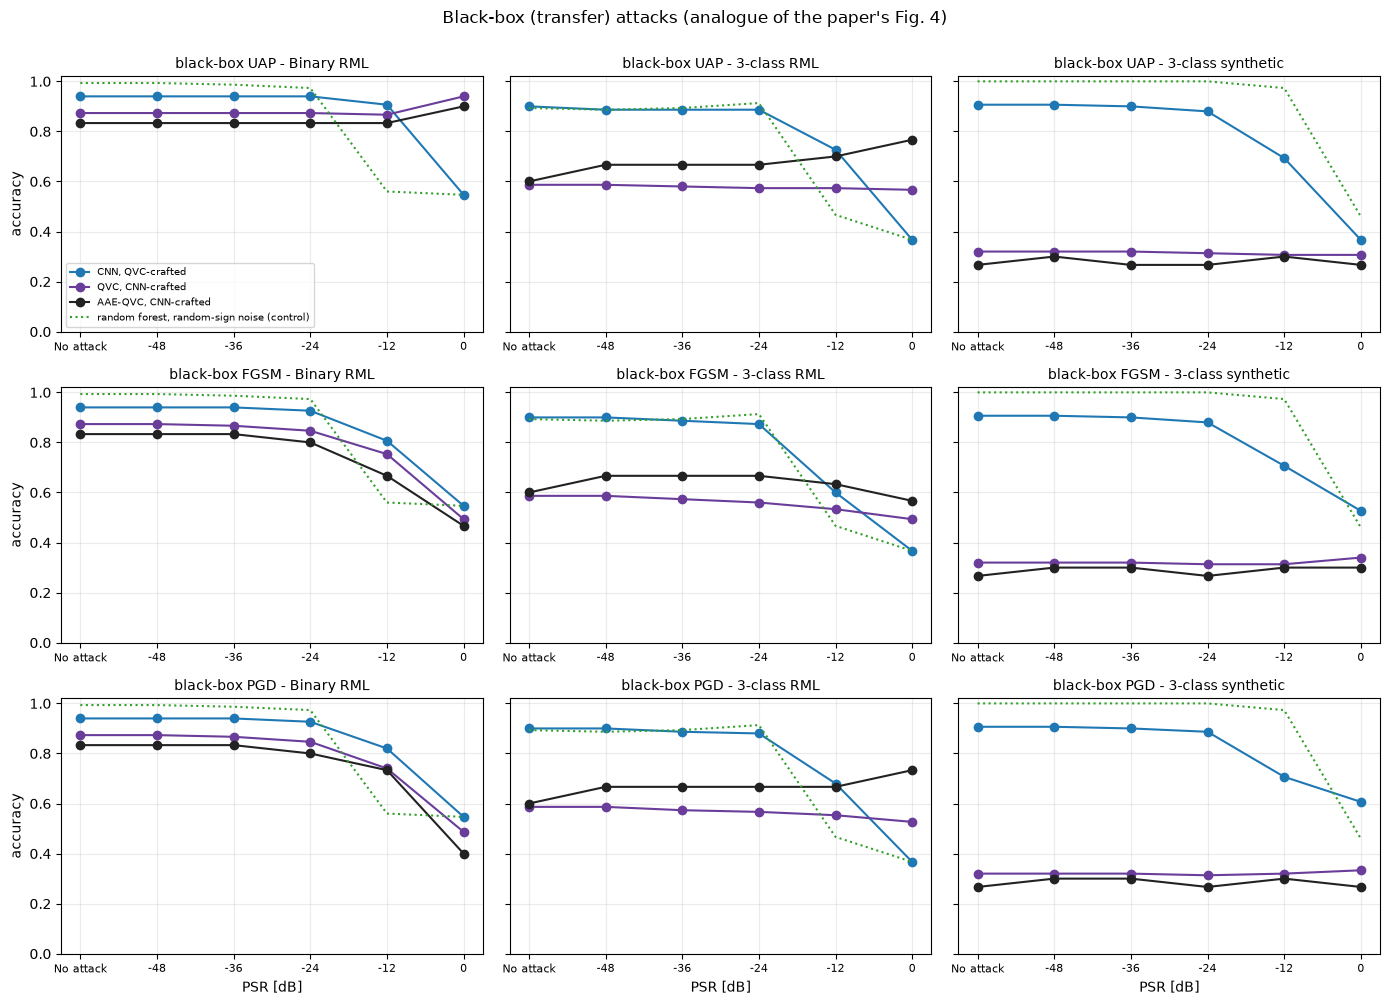

In [30]:
fig, axs = plt.subplots(3, 3, figsize=(14, 10), sharey=True)
xs = list(range(len(PSR_GRID) + 1))
for r, a in enumerate(["UAP", "FGSM", "PGD"]):
    for c, task in enumerate(TASKS):
        ax = axs[r, c]; t = TASKS[task]; A = AAE[task]; n = min(AAE_ADV_N, len(A["te_idx"]))
        clean_aae = float((predict(AsStates(AAE_MODELS[task]), A["S_te"][:n]) == t["yte"][A["te_idx"][:n]]).float().mean())
        curves = [("CNN, QVC-crafted", "CNN", [acc_of((task, "CNN", "clean", None))] + [BB[(task, "QVC", "CNN", a, p)] for p in PSR_GRID]),
                  ("QVC, CNN-crafted", "QVC", [acc_of((task, "QVC", "clean", None))] + [BB[(task, "CNN", "QVC", a, p)] for p in PSR_GRID]),
                  ("AAE-QVC, CNN-crafted", "AAE-QVC", [clean_aae] + [AAE_BB[(task, a, p)] for p in PSR_GRID])]
        for lab, ckey, ys_ in curves:
            ax.plot(xs, ys_, "o-", color=COL[ckey], label=lab)
        ax.plot(xs, [victim_acc(task, "RF", t["Xte"][att_idx(t)])] + [BB[(task, "CNN", "RF", "noise", p)] for p in PSR_GRID], ":", color=COL["RF"], label="random forest, random-sign noise (control)")
        ax.set_xticks(xs); ax.set_xticklabels(["No attack"] + [str(p) for p in PSR_GRID], fontsize=8)
        ax.set_title(f"black-box {a} - {task}", fontsize=10); ax.set_ylim(0, 1.02)
        if c == 0: ax.set_ylabel("accuracy")
        if r == 2: ax.set_xlabel("PSR [dB]")
        if r == 0 and c == 0: ax.legend(fontsize=7)
plt.suptitle("Black-box (transfer) attacks (analogue of the paper's Fig. 4)", y=1.0)
plt.tight_layout(); plt.show()

### Table 2: encoding depth against fidelity and accuracy (3-class RML)

For each number of AAE layers the encoder is trained on a training subset and a test subset of the 3-class task, the QVC-30 is
fine-tuned on the approximate training states, and accuracy is measured on the approximate test states. The reference row
(exact encoding) evaluates the exact-encoding QVC on the same test subset. A layer has 31 gates, so d layers cost 31 d gates.

   3 layers done [14 s]


   5 layers done [35 s]
layers  fidelity  accuracy   gates  paper_fidelity  paper_accuracy  paper_gates
     3     0.633     0.517  93.000           0.731           0.746           93
     5     0.793     0.550 155.000           0.895           0.775          155
 exact     1.000     0.683 963.067           1.000           0.812          973


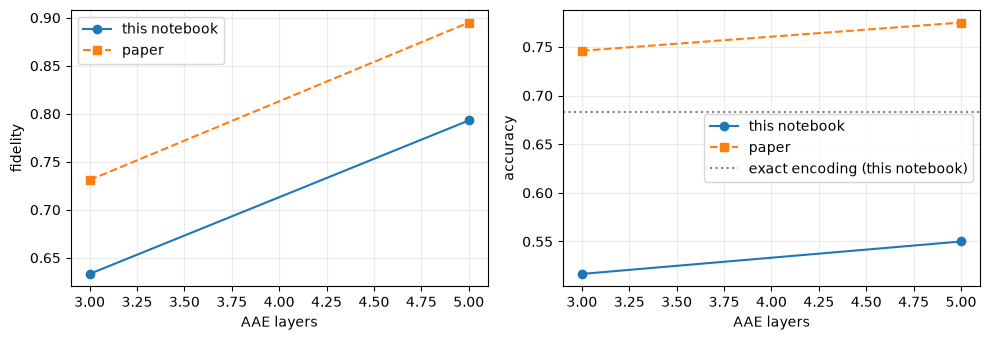

In [31]:
t3 = TASKS["3-class RML"]
sel_tr = torch.cat([torch.where(t3["ytr"] == c)[0][:T2_TRAIN_PER_CLASS] for c in range(3)])
sel_te = torch.cat([torch.where(t3["yte"] == c)[0][:T2_TEST_PER_CLASS] for c in range(3)])
PAPER_T2 = {3: (0.731, 0.746, 93), 5: (0.895, 0.775, 155), 10: (0.944, 0.779, 310), 15: (0.951, 0.785, 465), 20: (0.988, 0.803, 620)}
T2, t0 = [], time.time()
for d in T2_DEPTHS:
    S_a, _, _ = aae_encode(t3["Xtr"][sel_tr], d, AAE_ITERS, AAE_LR, seed=SEED)
    S_b, f_b, _ = aae_encode(t3["Xte"][sel_te], d, AAE_ITERS, AAE_LR, seed=SEED + 1)
    q = finetune_on_states(MODELS["3-class RML"]["qvc"], S_a, t3["ytr"][sel_tr], AAE_FT_EPOCHS, SEED)
    acc = float((predict(AsStates(q), S_b) == t3["yte"][sel_te]).float().mean())
    T2.append(dict(layers=d, fidelity=f_b.mean().item(), accuracy=acc, gates=31 * d,
                   paper_fidelity=PAPER_T2[d][0], paper_accuracy=PAPER_T2[d][1], paper_gates=PAPER_T2[d][2]))
    print(f"  {d:2d} layers done [{time.time() - t0:.0f} s]")
acc_exact_sub = accuracy(MODELS["3-class RML"]["qvc"], t3["Xte"][sel_te], t3["yte"][sel_te])
T2 = pd.DataFrame(T2)
T2.loc[len(T2)] = dict(layers="exact", fidelity=1.0, accuracy=acc_exact_sub, gates=EXACT_GATES, paper_fidelity=1.0, paper_accuracy=0.812, paper_gates=973)
print(T2.round(3).to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
d_ = T2[T2.layers != "exact"]
ax[0].plot(d_.layers.astype(int), d_.fidelity, "o-", label="this notebook"); ax[0].plot(d_.layers.astype(int), d_.paper_fidelity, "s--", label="paper"); ax[0].set_xlabel("AAE layers"); ax[0].set_ylabel("fidelity"); ax[0].legend()
ax[1].plot(d_.layers.astype(int), d_.accuracy, "o-", label="this notebook"); ax[1].plot(d_.layers.astype(int), d_.paper_accuracy, "s--", label="paper")
ax[1].axhline(acc_exact_sub, color="gray", ls=":", label="exact encoding (this notebook)"); ax[1].set_xlabel("AAE layers"); ax[1].set_ylabel("accuracy"); ax[1].legend()
plt.tight_layout(); plt.show()

## 8. Detectability of the adversarial signals: the Kolmogorov-Smirnov test (Table 3, RQ2)

Following the paper's Algorithm 2, an adversarial signal is *imperceptible* if the two-sample KS test (alpha = 0.05) cannot tell
it from at least one original signal; the table reports the share of adversarial signals for which **no** original matches
("detectable", out-of-distribution). Each signal's 256 amplitudes are treated as one sample. The KS statistic is computed for all
pairs in a vectorised way (and checked against `scipy.stats.ks_2samp`); the decision uses the critical value of the Kolmogorov
distribution for 256 vs 256 samples. The adversarial signals are test signals, the originals are random training signals of all
three classes. White-box FGSM, PGD and UAP are crafted on the QVC and on the CNN at the PSR values of the paper's Table 3.

In [32]:
from scipy import stats as sps

def ks_stat_pairs(A, O):
    """Two-sample Kolmogorov-Smirnov statistic D for every (adversarial signal, original signal) pair.
    A (a, n) and O (o, n) hold n amplitudes per signal; returns D (a, o). Vectorised with sorted samples."""
    a, n = A.shape
    o, m = O.shape
    As, _ = torch.sort(A, 1)
    Os, _ = torch.sort(O, 1)
    out = torch.empty(a, o)
    ka = torch.arange(1, n + 1, dtype=torch.float32) / n
    ko = torch.arange(1, m + 1, dtype=torch.float32) / m
    for i in range(a):
        Ai = As[i].unsqueeze(0).expand(o, n).contiguous()
        fo_at_a = torch.searchsorted(Os.contiguous(), Ai, right=True).float() / m      # F_O(a_k)
        d1 = torch.maximum((ka - fo_at_a).abs(), (ka - 1.0 / n - fo_at_a).abs()).max(1).values
        fa_at_o = torch.searchsorted(Ai[:1].expand(o, n).contiguous(), Os, right=True).float() / n   # F_A(o_k)
        d2 = torch.maximum((ko - fa_at_o).abs(), (ko - 1.0 / m - fa_at_o).abs()).max(1).values
        out[i] = torch.maximum(d1, d2)
    return out

def ks_detectable_fraction(Xadv, Xorig, alpha=0.05):
    """Paper's Algorithm 2: an adversarial signal is imperceptible if the KS test does not reject (p > alpha) for at least
    one original signal. Returns the fraction of adversarial signals that match NO original signal (out-of-distribution)."""
    n = Xadv.shape[1]
    D = ks_stat_pairs(Xadv, Xorig)
    en = n * Xorig.shape[1] / (n + Xorig.shape[1])
    d_crit = sps.kstwo.isf(alpha, np.round(en))             # p(D) = kstwo.sf(D, en) is monotone: p > alpha  <=>  D < d_crit
    return float((D.min(1).values.numpy() >= d_crit).mean())

ks_stat_pairs == scipy.stats.ks_2samp.statistic (max difference < 1e-6)


  FGSM done [9 s]


  PGD done [22 s]


  UAP done [34 s]


control: 4.4 % of the UNPERTURBED test signals are already 'detectable' against these 90 originals (the floor of the test; the paper's lowest values are 0.1-0.3 %)
share of detectable (out-of-distribution) adversarial signals, %  (3-class RML, white-box):
attack  PSR  paper_QVC  paper_CNN  ours_QVC  ours_CNN
  FGSM  -58        0.3        1.1       4.4       4.4
  FGSM  -42        0.3        2.1       4.4       4.4
  FGSM  -35        0.5        4.5       4.4       4.4
  FGSM  -28        0.7        6.7       2.2       6.7
  FGSM  -25        2.4       14.9       2.2       4.4
   PGD  -48        0.3        0.3       4.4       4.4
   PGD  -38        0.3        2.1       4.4       4.4
   PGD  -25        0.6        6.1       2.2       4.4
   PGD  -18        1.7       18.5       2.2       8.9
   PGD  -15        2.4       28.1       2.2       8.9
   UAP  -42        0.3        0.1       4.4       6.7
   UAP  -32        0.5        0.2       4.4       6.7
   UAP  -22        2.7        1.9       4.

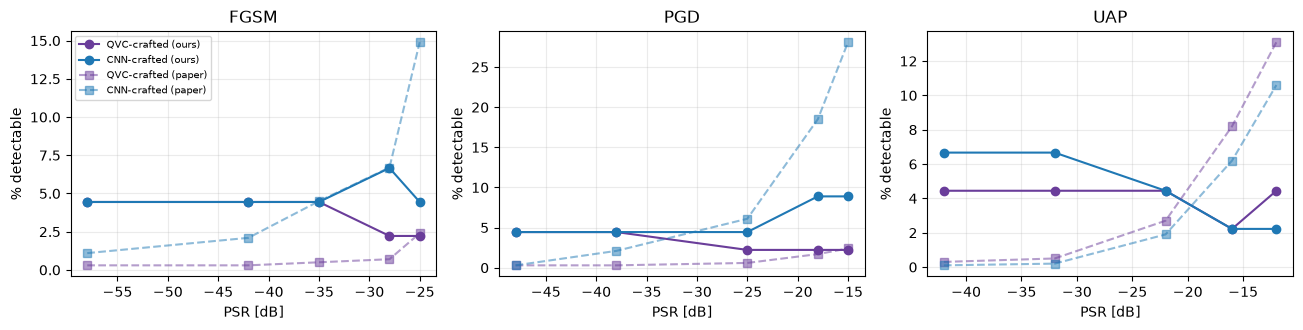

In [33]:
# the vectorised statistic equals scipy's
A_ = torch.tensor(np.random.default_rng(0).normal(size=(4, 256)), dtype=torch.float32); O_ = torch.tensor(np.random.default_rng(1).normal(size=(5, 256)), dtype=torch.float32)
ref_ = np.array([[sps.ks_2samp(a.numpy(), o.numpy()).statistic for o in O_] for a in A_])
assert np.abs(ks_stat_pairs(A_, O_).numpy() - ref_).max() < 1e-6
print("ks_stat_pairs == scipy.stats.ks_2samp.statistic (max difference < 1e-6)")

PAPER_T3 = {"FGSM": ([-58, -42, -35, -28, -25], [0.3, 0.3, 0.5, 0.7, 2.4], [1.1, 2.1, 4.5, 6.7, 14.9]),
            "PGD":  ([-48, -38, -25, -18, -15], [0.3, 0.3, 0.6, 1.7, 2.4], [0.3, 2.1, 6.1, 18.5, 28.1]),
            "UAP":  ([-42, -32, -22, -16, -12], [0.3, 0.5, 2.7, 8.2, 13.1], [0.1, 0.2, 1.9, 6.2, 10.6])}
t3 = TASKS["3-class RML"]
g_ = torch.Generator().manual_seed(SEED)
ks_adv_idx = att_idx(t3)[:KS_N_ADV]
ks_orig = t3["Xtr"][torch.randperm(len(t3["Xtr"]), generator=g_)[:KS_N_ORIG]]
T3, t0 = [], time.time()
for a, (psrs, pq, pc) in PAPER_T3.items():
    for psr, p_q, p_c in zip(psrs, pq, pc):
        row = dict(attack=a, PSR=psr, paper_QVC=p_q, paper_CNN=p_c)
        for mname in ["QVC", "CNN"]:
            model = MODELS["3-class RML"]["qvc" if mname == "QVC" else "cnn"]
            X, y = t3["Xte"][ks_adv_idx], t3["yte"][ks_adv_idx]
            if a == "FGSM": Xa = fgsm(model, X, y, psr)
            elif a == "PGD": Xa = pgd(model, X, y, psr, steps=PGD_STEPS, seed=SEED)
            else:
                Xs_ = t3["Xtr"][:UAP_SUBSET]; Xa = X + uap(model, Xs_, t3["ytr"][:UAP_SUBSET], psr, Xs_.pow(2).mean().item())
            row[f"ours_{mname}"] = 100 * ks_detectable_fraction(Xa, ks_orig, KS_ALPHA)
        T3.append(row)
    print(f"  {a} done [{time.time() - t0:.0f} s]")
T3 = pd.DataFrame(T3)
KS_CLEAN = 100 * ks_detectable_fraction(t3["Xte"][ks_adv_idx], ks_orig, KS_ALPHA)
print(f"control: {KS_CLEAN:.1f} % of the UNPERTURBED test signals are already 'detectable' against these {KS_N_ORIG} originals "
      f"(the floor of the test; the paper's lowest values are 0.1-0.3 %)")
print("share of detectable (out-of-distribution) adversarial signals, %  (3-class RML, white-box):")
print(T3.round(1).to_string(index=False))
fig, axs = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, a in zip(axs, PAPER_T3):
    d_ = T3[T3.attack == a]
    ax.plot(d_.PSR, d_.ours_QVC, "o-", color=COL["QVC"], label="QVC-crafted (ours)"); ax.plot(d_.PSR, d_.ours_CNN, "o-", color=COL["CNN"], label="CNN-crafted (ours)")
    ax.plot(d_.PSR, d_.paper_QVC, "s--", color=COL["QVC"], alpha=0.5, label="QVC-crafted (paper)"); ax.plot(d_.PSR, d_.paper_CNN, "s--", color=COL["CNN"], alpha=0.5, label="CNN-crafted (paper)")
    ax.set_title(a); ax.set_xlabel("PSR [dB]"); ax.set_ylabel("% detectable")
axs[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 9. Depolarising noise (Fig. 6, RQ4)

A depolarising channel of probability 0.02 (Kraus operators sqrt(1-p) I and sqrt(p/3) X, Y, Z) acts on every qubit after every layer of
the encoder (5 layers) and of the classifier (30 layers). The state is then a 256 x 256 density matrix, simulated exactly. For the
classifier the noisy circuit is turned into a fixed 256 x 256 observable per class (Heisenberg picture), so training stays
differentiable. The simulators are asserted equal to PennyLane's `default.mixed` device.

Two choices the paper leaves open: the encoder angles are the noiseless ones found in Section 7 (noise acts when the circuit is
executed), and, because 35 noisy layers shrink every expectation value to about 0.01, the noisy classifier uses a trainable positive
output scale before the softmax (it cannot change the predicted class). Only the 3-class RML task is studied, as in the paper.

In [34]:
GINV_RING, GINV_CHAIN = torch.argsort(G_RING), torch.argsort(G_CHAIN)

def _blocks(theta, dagger):
    U = rot_mats(theta)                                         # (..., 8, 2, 2)
    Ka = kron2(kron2(U[..., 0, :, :], U[..., 1, :, :]), kron2(U[..., 2, :, :], U[..., 3, :, :]))
    Kb = kron2(kron2(U[..., 4, :, :], U[..., 5, :, :]), kron2(U[..., 6, :, :], U[..., 7, :, :]))
    return (Ka.mH, Kb.mH) if dagger else (Ka, Kb)

def left_W(M, theta, gather, dagger=False):
    """Left-multiply matrices M (B, 256, N) by one layer W = P (Ka x Kb) of the circuit, or by W^dagger.
    theta (8, 3) shared, or (B, 8, 3) one layer per sample."""
    B, _, N = M.shape
    Ka, Kb = _blocks(theta, dagger)
    if dagger:                                                  # W^dagger = (Ka x Kb)^dagger P^T
        M = M[:, torch.argsort(gather), :]
    M = (Ka @ M.reshape(B, 16, 16 * N)).reshape(B, 16, 16, N)
    M = (Kb.unsqueeze(-3) @ M if Kb.dim() == 3 else Kb @ M).reshape(B, DIM, N)
    if not dagger:
        M = M[:, gather, :]
    return M

def depolarize(M, p):
    """Depolarising channel of probability p on every qubit of a batch of 256 x 256 operators (it is its own adjoint):
    E(M) = (1-p) M + p/3 (X M X + Y M Y + Z M Z) = (1 - 4p/3) M + (2p/3) Tr_q(M) (x) I_q."""
    B = M.shape[0]
    eye = torch.eye(2, dtype=M.dtype)
    for q in range(NQ):
        l, r = 2 ** q, 2 ** (NQ - 1 - q)
        M7 = M.reshape(B, l, 2, r, l, 2, r)
        tr = torch.einsum("bicjkcl->bijkl", M7)                 # partial trace over qubit q
        M = ((1 - 4 * p / 3) * M7 + (2 * p / 3) * torch.einsum("bijkl,cd->bicjkdl", tr, eye)).reshape(B, DIM, DIM)
    return M

def noisy_state(theta, layers_gather, p, n=None):
    """Density matrices (B, 256, 256) of U(theta)|0> when a depolarising channel of probability p follows every layer.
    theta (B, L, 8, 3)."""
    B, L = theta.shape[0], theta.shape[1]
    rho = torch.zeros(B, DIM, DIM, dtype=CDT)
    rho[:, 0, 0] = 1
    for l in range(L):
        rho = left_W(left_W(rho, theta[:, l], layers_gather).mH, theta[:, l], layers_gather)   # W rho W^dagger
        rho = depolarize(rho, p)
    return rho

def noisy_observables(theta_cls, n_out, p):
    """Heisenberg picture of the noisy QVC: O_c = E1^+ ... with <Z_c> = Tr(O_c rho_in). theta_cls (L, 8, 3)."""
    L = theta_cls.shape[0]
    O = torch.diag_embed(ZMAT[:, :n_out].T.to(CDT))              # (C, 256, 256)
    for l in reversed(range(L)):
        O = depolarize(O, p)                                    # adjoint of the channel that follows layer l
        O = left_W(left_W(O, theta_cls[l].expand(n_out, -1, -1), G_RING, dagger=True).mH,
                   theta_cls[l].expand(n_out, -1, -1), G_RING, dagger=True)                    # W^dagger O W
    return O

In [35]:
# ---- equivalence with PennyLane's mixed-state simulator (tiny circuit: 2 encoder layers + 3 classifier layers) ----
rs = np.random.default_rng(3)
Le_, Lc_, C_ = 2, 3, 3
th_e = torch.tensor(rs.uniform(0, 2 * np.pi, (1, Le_, 8, 3)), dtype=RDT); th_c = torch.tensor(rs.uniform(0, 2 * np.pi, (Lc_, 8, 3)), dtype=RDT)
mine_ = torch.einsum("cij,bji->bc", noisy_observables(th_c, C_, NOISE_P), noisy_state(th_e, G_CHAIN, NOISE_P)).real.numpy()[0]
dev_m = qml.device("default.mixed", wires=8)
@qml.qnode(dev_m)
def noisy_ref(te, tc):
    for l in range(Le_):
        aae_layer(te[l])
        for w in range(8): qml.DepolarizingChannel(NOISE_P, wires=w)
    for l in range(Lc_):
        qvc_layer(tc[l])
        for w in range(8): qml.DepolarizingChannel(NOISE_P, wires=w)
    return [qml.expval(qml.PauliZ(c)) for c in range(C_)]
ref_ = np.array(noisy_ref(th_e[0].numpy().astype(np.float64), th_c.numpy().astype(np.float64)))
assert np.abs(ref_ - mine_).max() < 1e-5, (ref_, mine_)
print(f"noisy simulator vs PennyLane default.mixed: max difference {np.abs(ref_ - mine_).max():.1e} -> equal")

noisy simulator vs PennyLane default.mixed: max difference 5.9e-08 -> equal


In [36]:
task = "3-class RML"; t = TASKS[task]; A = AAE[task]
def noisy_rho(theta, chunk=24):
    return torch.cat([noisy_state(theta[i:i + chunk], G_CHAIN, NOISE_P) for i in range(0, len(theta), chunk)])

# noisy training signals: a subset of the AAE training signals (density matrices are 0.5 MB each)
nz_tr = torch.cat([torch.where(t["ytr"][A["tr_idx"]] == c)[0][:NOISE_TRAIN_PER_CLASS] for c in range(3)])
t0 = time.time()
rho_tr = noisy_rho(A["th_tr"][nz_tr]); y_nz = t["ytr"][A["tr_idx"]][nz_tr]
theta_nz = nn.Parameter(AAE_MODELS[task].theta.detach().clone())          # start from the noiseless AAE-QVC
log_scale = nn.Parameter(torch.tensor(float(np.log(30.0))))
opt = torch.optim.Adam([theta_nz, log_scale], lr=1e-2)
for step in range(NOISE_STEPS):
    opt.zero_grad()
    O = noisy_observables(theta_nz, 3, NOISE_P)
    lg = torch.einsum("cij,bji->bc", O, rho_tr).real * log_scale.exp()
    loss = F.cross_entropy(lg, y_nz); loss.backward(); opt.step()
    if step % 10 == 0 or step == NOISE_STEPS - 1:
        print(f"  noisy step {step:3d} loss {loss.item():.4f} acc {(lg.argmax(1) == y_nz).float().mean():.3f} ({time.time() - t0:.0f} s)")
with torch.no_grad():
    O_NOISY = noisy_observables(theta_nz, 3, NOISE_P)
def noisy_predict(theta_enc):
    rho = noisy_rho(theta_enc)
    return torch.einsum("cij,bji->bc", O_NOISY, rho).real.argmax(1)
print("typical size of a noisy <Z> output:", float(torch.einsum("cij,bji->bc", O_NOISY, rho_tr[:20]).real.abs().mean()))

  noisy step   0 loss 0.8993 acc 0.667 (48 s)


  noisy step   1 loss 0.8840 acc 0.633 (78 s)


typical size of a noisy <Z> output: 0.009940220974385738


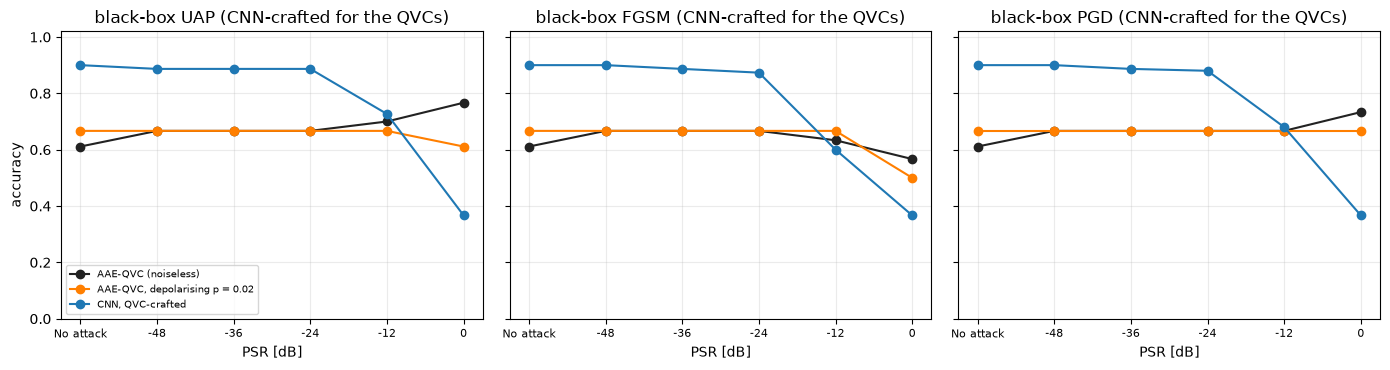

3-class RML, 18 signals: noiseless AAE-QVC 0.611 -> noisy 0.667


In [37]:
n = min(NOISE_TEST_N, AAE_ADV_N, len(A["te_idx"]))
y_n = t["yte"][A["te_idx"][:n]]
NZ = {"clean": float((noisy_predict(A["th_te"][:n]) == y_n).float().mean())}
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
xs = list(range(len(PSR_GRID) + 1))
clean_aae = float((predict(AsStates(AAE_MODELS[task]), A["S_te"][:n]) == y_n).float().mean())
for ax, a in zip(axs, ["UAP", "FGSM", "PGD"]):
    ys_nz = [NZ["clean"]]
    for psr in PSR_GRID:
        NZ[(a, psr)] = float((noisy_predict(ADV_TH[(task, a, psr)][:n]) == y_n).float().mean()); ys_nz.append(NZ[(a, psr)])
    ax.plot(xs, [clean_aae] + [AAE_BB[(task, a, p)] for p in PSR_GRID], "o-", color=COL["AAE-QVC"], label="AAE-QVC (noiseless)")
    ax.plot(xs, ys_nz, "o-", color=COL["noisy"], label=f"AAE-QVC, depolarising p = {NOISE_P}")
    ax.plot(xs, [acc_of((task, "CNN", "clean", None))] + [BB[(task, "QVC", "CNN", a, p)] for p in PSR_GRID], "o-", color=COL["CNN"], label="CNN, QVC-crafted")
    ax.set_xticks(xs); ax.set_xticklabels(["No attack"] + [str(p) for p in PSR_GRID], fontsize=8); ax.set_title(f"black-box {a} (CNN-crafted for the QVCs)"); ax.set_xlabel("PSR [dB]"); ax.set_ylim(0, 1.02)
axs[0].set_ylabel("accuracy"); axs[0].legend(fontsize=7)
plt.tight_layout(); plt.show()
print(f"3-class RML, {n} signals: noiseless AAE-QVC {clean_aae:.3f} -> noisy {NZ['clean']:.3f}")

## 10. Paper versus this notebook: a verdict per claim

Each row is one number or statement of the paper. **reproduced**: within 2 accuracy points (0.02; for percentages 2 points; for
parameter counts exact; for gate counts 5 %); **not reached** / **exceeded**: outside the tolerance, with the gap; **cannot be
checked**: the quantity was not run in this budget or is not defined well enough. In `FAST_MODE` most numbers are far from the
paper's because only a few dozen signals and a few epochs are used.

The committed run is the FAST run, so the verdicts compare the paper's full-size numbers with models trained on a few hundred signals for a few dozen epochs. Read every "not reached" below as "not reached in this budget", not as a refutation.

In [38]:
V = []
def verdict(paper, ours, tol, rel=False):
    if ours is None or (isinstance(ours, float) and np.isnan(ours)): return "cannot be checked"
    gap = ours - paper
    lim = tol * abs(paper) if rel else tol
    return "reproduced" if abs(gap) <= lim else ("exceeded" if gap > 0 else "not reached")
def add(claim, paper, ours, tol, rel=False, fmt="{:.3f}"):
    v = verdict(paper, ours, tol, rel) if paper is not None else "cannot be checked"
    V.append(dict(claim=claim, paper=fmt.format(paper) if paper is not None else "-", notebook=fmt.format(ours) if ours is not None else "-",
                  gap=(fmt.format(ours - paper) if (paper is not None and ours is not None) else "-"), verdict=v))

for task in TASKS:
    for col, pcol, nm in [("CNN", "paper_CNN", "CNN"), ("QVC30", "paper_QVC30", "QVC-30"), ("AAE_QVC30", "paper_AAE", "5AAE-QVC-30")]:
        add(f"Table 1 accuracy, {task}, {nm}", T1.loc[task, pcol], T1.loc[task, col], TOL)
for _, r in T2.iterrows():
    if r.layers == "exact":
        add("Table 2 accuracy, exact encoding", r.paper_accuracy, r.accuracy, TOL); add("Table 2 gates, exact encoding (973)", r.paper_gates, r.gates, 0.05, rel=True, fmt="{:.0f}")
    else:
        add(f"Table 2 fidelity, {r.layers} layers", r.paper_fidelity, r.fidelity, TOL); add(f"Table 2 accuracy, {r.layers} layers", r.paper_accuracy, r.accuracy, TOL)
        add(f"Table 2 gates, {r.layers} layers (31 per layer)", r.paper_gates, r.gates, 0.0, fmt="{:.0f}")
add("5-layer mean fidelity 0.8957 (10 repetitions)", 0.8957, FID_MEAN, TOL, fmt="{:.4f}")
add("fidelity spread over repetitions (0.0003)", 0.0003, FID_STD, 0.002, fmt="{:.4f}")
add("Table A3 CNN parameters, binary", 133298, sum(p.numel() for p in CNN(2, 1.0).parameters()), 0, fmt="{:,.0f}")
add("Table A3 CNN parameters, 3-class", 133315, sum(p.numel() for p in CNN(3, 1.0).parameters()), 0, fmt="{:,.0f}")
add("Table A3 QVC-30 gates (1,933)", 1933, EXACT_GATES + 960, 0.05, rel=True, fmt="{:.0f}")
add("Table A3 5AAE-QVC-30 gates (1,115)", 1115, 5 * 31 + 960, 0.0, fmt="{:.0f}")
for _, r in T3.iterrows():
    for nm in ["QVC", "CNN"]:
        add(f"Table 3 detectable %, {r.attack} {r.PSR} dB, {nm}-crafted", r[f"paper_{nm}"], r[f"ours_{nm}"], 2.0, fmt="{:.1f}")

def qual(claim, ok, detail):
    V.append(dict(claim=claim, paper="(qualitative)", notebook=detail, gap="-", verdict="reproduced" if ok else "not reached"))
# Fig. 3 / white-box
win, tot = 0, 0
for task in TASKS:
    for a in ["UAP", "FGSM", "PGD"]:
        q_ = np.mean([acc_of((task, "QVC", a, p)) for p in PSR_GRID]); c_ = np.mean([acc_of((task, "CNN", a, p)) for p in PSR_GRID])
        win += q_ >= c_; tot += 1
qual("Fig. 3: QVC generally slightly more robust than CNN in white-box attacks", win >= 0.5 * tot + 0.5, f"QVC mean accuracy over the PSR grid >= CNN in {win} of {tot} task/attack pairs")
low = np.mean([acc_of((tk, "QVC", a, 0)) for tk in TASKS for a in ["FGSM", "PGD"]])
qual("Fig. 3: QVC still collapses under strong white-box attacks", low <= 0.5, f"mean QVC accuracy under FGSM/PGD at 0 dB = {low:.2f}")
# Fig. 4 / black-box
drops_c, drops_q = [], []
for task in TASKS:
    for a in ["FGSM", "PGD", "UAP"]:
        for p in [x for x in PSR_GRID if x >= -24]:
            drops_c.append(acc_of((task, "CNN", "clean", None)) - BB[(task, "QVC", "CNN", a, p)])
            drops_q.append(acc_of((task, "QVC", "clean", None)) - BB[(task, "CNN", "QVC", a, p)])
qual("Fig. 4: QVC-crafted attacks transfer to the CNN more strongly than CNN-crafted attacks transfer to the QVC (PSR >= -24 dB)",
     np.mean(drops_c) > np.mean(drops_q), f"mean accuracy drop of the CNN {np.mean(drops_c):.2f} vs of the QVC {np.mean(drops_q):.2f}")
cnn_pgd = [BB[("3-class RML", "QVC", "CNN", "PGD", p)] for p in PSR_GRID]
V.append(dict(claim="Fig. 4 text: 3-class black-box PGD takes the CNN from 96.7 % to 43.4 % (PSR not stated)", paper="0.967 -> 0.434",
              notebook=f"{acc_of(('3-class RML', 'CNN', 'clean', None)):.3f} -> min {min(cnn_pgd):.3f} over the grid (-12 dB: {BB[('3-class RML', 'QVC', 'CNN', 'PGD', -12)]:.3f})",
              gap="-", verdict="cannot be checked"))
V.append(dict(claim="(extra, not in the paper) CNN-crafted PGD transferred to QVC, RF and SVC, 3-class RML", paper="-",
              notebook=f"{ADAPT_LEVELS[-1]} dB: QVC {BB[('3-class RML','CNN','QVC','PGD',ADAPT_LEVELS[-1])]:.2f}, RF {BB[('3-class RML','CNN','RF','PGD',ADAPT_LEVELS[-1])]:.2f}, SVC {BB[('3-class RML','CNN','SVC','PGD',ADAPT_LEVELS[-1])]:.2f}; clean QVC {acc_of(('3-class RML','QVC','clean',None)):.2f}, RF {victim_acc('3-class RML','RF',TASKS['3-class RML']['Xte'][att_idx(TASKS['3-class RML'])]):.2f}",
              gap="-", verdict="informative"))
V.append(dict(claim="(extra) gradient-masking indicators (Section 5)", paper="-", notebook=f"{len(GM_FLAGS)} indicator(s) raised", gap="-", verdict="informative"))
V.append(dict(claim="(extra) KS floor: unperturbed signals flagged as detectable", paper="0.1-0.3 % lowest", notebook=f"{KS_CLEAN:.1f} %", gap="-", verdict="informative"))
# Table 3 ordering
for a, want_q_lower in [("FGSM", True), ("PGD", True), ("UAP", False)]:
    d_ = T3[T3.attack == a]
    q_lower = (d_.ours_QVC <= d_.ours_CNN).mean() >= 0.6
    qual(f"Table 3: {a}-adversarial signals from the QVC are " + ("less" if want_q_lower else "more") + " detectable than from the CNN", q_lower == want_q_lower,
         f"QVC-crafted <= CNN-crafted at {(d_.ours_QVC <= d_.ours_CNN).sum()} of 5 PSR values")
# Fig. 6 noise
drop_clean = clean_aae - NZ["clean"]
qual("Fig. 6: depolarising noise (p = 0.02) lowers the accuracy significantly", drop_clean >= 0.05, f"clean accuracy {clean_aae:.2f} -> {NZ['clean']:.2f}")
rel_nz = np.mean([NZ[(a, p)] - NZ["clean"] for a in ["UAP", "FGSM", "PGD"] for p in PSR_GRID if p >= -24])
rel_no = np.mean([AAE_BB[("3-class RML", a, p)] - clean_aae for a in ["UAP", "FGSM", "PGD"] for p in PSR_GRID if p >= -24])
qual("Fig. 6: noise does not change the QVC's robustness to CNN-crafted attacks", abs(rel_nz - rel_no) <= 0.05, f"mean accuracy change under attack: noisy {rel_nz:+.2f}, noiseless {rel_no:+.2f}")
V = pd.DataFrame(V)
pd.set_option("display.width", 250, "display.max_colwidth", 110, "display.max_rows", 500)
print(V.to_string(index=False))
print("\nVerdict counts:"); print(V.verdict.value_counts().to_string())
print("Gradient-masking indicators raised in Section 5:", len(GM_FLAGS))

                                                                                                                     claim            paper                                                               notebook     gap           verdict
                                                                                         Table 1 accuracy, Binary RML, CNN            0.995                                                                  0.940  -0.055       not reached
                                                                                      Table 1 accuracy, Binary RML, QVC-30            0.993                                                                  0.883  -0.110       not reached
                                                                                 Table 1 accuracy, Binary RML, 5AAE-QVC-30            0.992                                                                  0.875  -0.117       not reached
                                                    

## Reading the paper critically

All statements about *this notebook* refer to the executed FAST run (small samples, short budgets); they are evidence, not proof.

**1. The data cannot be what the paper says.** RML2016.10a holds 1000 signals per modulation and SNR, so the paper's 5000 training
and 500 test signals per class at 16 dB cannot be drawn from it (the 10b variant has 6000, but the paper describes 10a: 200,000
signals, 20 SNRs). The paper does not say how the sample was built, so even the sample size is not reproducible from the text.

**2. The quantum model is the weakest classifier on the table.** In this run the 30-layer QVC reached 0.88 (binary RML), 0.65
(3-class RML) and 0.36 (synthetic, i.e. close to chance for three classes), against 0.94 / 0.88 / 0.92 for the CNN and
0.997 / 0.909 / 1.000 (random forest) and 0.990 / 0.749 / 0.931 (SVM) on the very same unit-length inputs the QVC receives. The paper's
own Table 1 also has the QVC below the CNN; here the gap to the classical baselines is larger, and the synthetic task shows that
a 720-angle circuit trained for 40 short epochs can fail to learn at all. Whether that is the budget, the read-out (Pauli-Z
expectations are confined to [-1, 1]) or the starting angles is not something this run can tell; the paper gives no training
curves, epochs or read-out to compare with.

**3. "Robust" must be separated from "insensitive".** Amplitude encoding divides every signal by its norm, so the QVC is blind to
a pure change of scale. In the 3-class task, random-sign noise at -12 dB lowers the CNN from 0.90 to 0.46 but leaves the QVC unchanged
(0.587 -> 0.573); that is insensitivity, not adversarial robustness. Under a *white-box* PGD at the same level the QVC falls to
0.29 (margin-loss PGD) and to 0 at 0 dB, so the exact-gradient attacker wins, which the paper also says. A margin-loss PGD, random
restarts and the per-signal worst case were no stronger than cross-entropy PGD on the QVC (differences of 0-3 points), and no
gradient-masking indicator of Section 5 was raised, so the QVC's white-box numbers are not an artefact of a weak attack. One caveat on
the *CNN*: for 5 % of the 3-class test signals the cross-entropy gradient is exactly zero (the softmax is saturated), those signals
receive no FGSM perturbation (the realised PSR printed in Section 4 is -inf dB on average for that reason); the margin-loss PGD
has no such blind spot, which is why the adaptive table matters for the classical model too.

**4. The black-box asymmetry is real here, but it is not specific to quantum models.** At PSR = -12 dB, PGD signals crafted on the
CNN lower the QVC from 0.587 to 0.553 on the 3-class task, while PGD signals crafted on the QVC lower the CNN from 0.90 to 0.68, the same
direction as the paper. But the same CNN-crafted signals leave an SVM on identical inputs almost untouched (0.70 -> 0.63) and
bring a random forest from 0.89 to 0.37. So "attacks crafted on the CNN do not transfer to the QVC" is also true for the SVM,
and false for the random forest; a CNN-to-anything transfer rate depends on how similar the victim's decision boundary is to the
CNN's, and a quantum circuit is just one dissimilar victim. The paper compares only with the CNN.

**5. Stealthiness (Table 3) rests on a test with a floor.** With 90 original signals the KS test already flags 4.4 % of the
*unperturbed* test signals as out-of-distribution (the paper's lowest entries are 0.1-0.3 %), so the low-PSR cells cannot be
compared; the paper does not say which originals or how many it used. FGSM and PGD signals crafted on the QVC were never more
detectable than those crafted on the CNN (5 of 5 PSR values each, the paper's direction) but the differences are one to three
signals out of 45; for UAP the paper's reversed ordering was not reproduced (4 of 5 values). A more power-preserving or
distribution-preserving perturbation would also be "stealthier" than either; the test only compares amplitude histograms.

**6. The AAE and the noise study are only partly checkable at this budget.** With 60 Adam iterations the 5-layer encoder reaches
a mean fidelity of 0.79 (paper 0.8957 after 300; the sensitivity cell shows 0.91 for small starting angles and 0.80 for large
ones, so the paper's number depends on an unreported initialisation). The fine-tuned AAE-QVC loses 0-8 points against the exact
QVC on the same signals; the depth sweep (3 and 5 layers only) shows fidelity and accuracy rising with depth, as the paper says. The
noise experiment used 18 signals and two optimisation steps; it neither shows the accuracy drop the paper reports (0.61 -> 0.67)
nor can it exclude it. The text's "360 trainable parameters" for 5 layers (24 per layer = 120) and the identical counts in Table A3
for binary and 3-class QVCs are internal inconsistencies of the preprint.

**7. Nothing here tests quantum hardware.** The conclusions concern exact noiseless simulation (and a depolarising model); the paper's
suggestion that AAE helps on real devices is not tested by either study.

## Exercises

1. **Full budget.** Set `FAST_MODE = False` in Colab (a free CPU runtime takes a few hours) and compare Table 1 and Table 2 with the FAST numbers. Which verdicts change? Is the synthetic-task QVC still near chance?
2. **Read-out and scale.** Replace the logits <Z_c> by 3 x <Z_c> or by the probabilities of three basis states, retrain the 3-class QVC, and report accuracy and white-box PGD accuracy at -24 dB. Does the QVC's apparent robustness change when its decision margin changes?
3. **A fairer transfer test.** Craft PGD on the SVM (use a differentiable RBF kernel in PyTorch) and on the random forest's smooth surrogate, then attack the QVC. Is the asymmetry still "quantum is special"?
4. **Attack the AAE-QVC directly.** The AAE is a differentiable circuit; backpropagate through its 300 Adam steps (or through a fixed number of unrolled steps) and run a white-box PGD on the AAE-QVC. Does the encoder's approximation add robustness, or only a harder-to-compute gradient?
5. **KS test floor.** Increase `KS_N_ORIG` until the unperturbed-signal floor is below 1 %, rerun Table 3, and decide which of the paper's ordering claims for FGSM, PGD and UAP survive.